In [ ]:
! pip install ONE-api
! pip install ibllib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 68.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 6.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.9/57.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 449.3/449.3 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.8/106.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.0/48.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.1/226.1

In [ ]:
from one.api import ONE
from brainbox.io.one import SessionLoader
ONE.setup(base_url='https://openalyx.internationalbrainlab.org', silent=True)
one = ONE(password='international')

Connected to https://openalyx.internationalbrainlab.org as user "intbrainlab"


In [ ]:
import warnings
from one.util import alferr

warnings.filterwarnings('ignore', category=alferr.ALFWarning)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from scipy import stats
import seaborn as sns

In [ ]:
SESSIONS_ACCURACY=pd.DataFrame(columns=['accuracy'])
PENALTY='l1'
PALETTE_MAP = {
    'block': '#6A5ACD',       # Slate Blue
    'contrast': '#20B2AA',    # Light Sea Green
    'choice': '#4682B4',      # Steel Blue
    'reward': '#FF8C00'       # Dark Orange
}
SESSIONS=[
    '837b4e6a-ccfd-49b0-a1dd-3aa53fbf2ecb', '9fc31d79-b56f-46d0-92a0-e9563caf4a7a', 'a7eba2cf-427f-4df9-879b-e53e962eae18', 'c8e11fd8-d130-4f06-abba-9aa20240ce7c',
    '500a71dd-8768-4211-a1fe-1fafc9fcbf29', 'a2b9fbbe-79fc-4166-a16e-b307813a2f06', 'fd03d365-91df-41e2-ad81-9e0e4b9f5c7b', '3a3ea015-b5f4-4e8b-b189-9364d1fc7435',
    'ebce500b-c530-47de-8cb1-963c552703ea', '7cc74598-9c1b-436b-84fa-0bf89f31adf6', '8c025071-c4f3-426c-9aed-f149e8f75b7b', 'f4eb56a4-8bf8-4bbc-a8f3-6e6535134bad',
    '5c0c560e-9e1f-45e9-b66e-e4ee7855be84', 'f56194bc-8215-4ae8-bc6a-89781ad8e050', '28338153-4113-485b-835b-91cb96d984f2', '7f150b7c-c261-46e6-9edb-cc391c9d9f03',
    '642c97ea-fe89-4ec9-8629-5e492ea4019d', 'd85c454e-8737-4cba-b6ad-b2339429d99b', '5437ec1f-6535-470c-80b8-4c8806ee085d', '75db708a-9952-4452-a5b1-a851d88f8e28',
    '29a6def1-fc5c-4eea-ac48-47e9b053dcb5', '61caa69d-088b-465a-b9d0-d75341dabac6', '233617ec-c5cf-4eda-afc8-3b1d94f36d73', '2038e95d-64d4-4ecb-83d0-1308d3c598f8',
    'e6bdb1f4-b0bf-4451-8f23-4384f2102f91', 'c958919c-2e75-435d-845d-5b62190b520e', '6bf810fd-fbeb-4eea-9ea7-b6791d002b22', '7eeb8423-49e6-4d40-ab6f-703d17af231a',
    '2d93903c-d02b-4e0d-9218-681f2884598d', '14127fdb-2e66-4823-b124-f49c128ba94d', '11163613-a6c9-4975-9586-84dc00481547', '6ab9d98c-b1e9-4574-b8fe-b9eec88097e0',
    '752456f3-9f47-4fbf-bd44-9d131c0f41aa', '62ff920c-2fdd-4feb-9d9f-0d66f2e595a1', '4546cd60-fa2a-4d20-a9b6-d091e01d16f2', '5ae68c54-2897-4d3a-8120-426150704385',
    'd23b005f-46f5-4fe1-870c-f55f6eb9533d', '36573e0b-ddd6-4504-94ec-9a23c877486c', 'cef05f87-161b-4031-932c-6f47daf89698', '7235b10c-6621-44ea-abe9-01559633472d'
]

print('Sessions count: '+str(len(SESSIONS)))

Sessions count: 40


In [ ]:
def plot_coefficients_distribution(coefficients_df, sample_counts=1000, confidence_level=0.95):
    """
    Generates a candlestick-like plot for the distribution of model coefficients across sessions,
    grouped by feature type (choice, reward, contrast), using bootstrapping.

    Args:
        coefficients_df (pd.DataFrame): DataFrame where rows are sessions and columns are feature coefficients.
        sample_counts (int): Number of bootstrapped samples to generate for each coefficient.
        confidence_level (float): The desired confidence level for the whiskers (e.g., 0.95 for 95% CI).
    """

    all_bootstrapped_data_for_plot = []

    # Helper to extract feature type and lag order for sorting and coloring
    def extract_feature_info(feature_name):
        if feature_name == 'contrast':
            return 'contrast', 0
        elif feature_name.startswith('choice_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'choice', lag
        elif feature_name.startswith('reward_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'reward', lag
        elif feature_name.startswith('contrast_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'contrast', lag
        elif feature_name == 'block': # Added this condition for 'block' feature
            return 'block', 0
        else:
            # Handle any other features or the main contrast if it's just 'contrast'
            return 'other', 0

    print(f"Generating {sample_counts} bootstrapped samples for each coefficient...")

    alpha = 1 - confidence_level
    lower_percentile = alpha / 2 * 100
    upper_percentile = (1 - alpha / 2) * 100

    # Process each coefficient (column) in the DataFrame
    for feature_name in coefficients_df.columns:
        feature_coeffs = coefficients_df[feature_name].values

        # Use the existing bootstrap_samples function
        bootstrapped_raw_samples = bootstrap_samples(feature_coeffs, sample_counts)
        bootstrapped_means = np.mean(bootstrapped_raw_samples, axis=1)

        # Calculate confidence interval for the bootstrapped means
        ci_lower = np.percentile(bootstrapped_means, lower_percentile)
        ci_upper = np.percentile(bootstrapped_means, upper_percentile)
        mean_of_means = np.mean(bootstrapped_means)

        print(f"\n--- Feature: {feature_name} ---")
        print(f"  Mean of bootstrapped coefficients: {mean_of_means:.4f}")
        print(f"  {confidence_level*100:.0f}% CI for Mean: [{ci_lower:.4f}, {ci_upper:.4f}]")

        # Extract feature type and lag information
        feature_type, lag_order = extract_feature_info(feature_name)

        # Create a temporary DataFrame for this feature's bootstrapped means
        temp_df = pd.DataFrame({
            'Feature': feature_name,
            'Feature_Type': feature_type,
            'Bootstrapped Coefficient Mean': bootstrapped_means,
            'Lag_Order': lag_order
        })
        all_bootstrapped_data_for_plot.append(temp_df)

    # Concatenate all temporary DataFrames into one for plotting
    plot_data = pd.concat(all_bootstrapped_data_for_plot)

    # Define the desired order for Feature_Type and then sort
    feature_type_order = ['block', 'contrast', 'choice', 'reward'] # Updated order to include 'block'
    plot_data['Feature_Type'] = pd.Categorical(plot_data['Feature_Type'], categories=feature_type_order, ordered=True)
    plot_data = plot_data.sort_values(by=['Feature_Type', 'Lag_Order'])

    # Create a custom palette based on the PALETTE_MAP and the feature_type_order
    custom_palette = [PALETTE_MAP[ftype] for ftype in feature_type_order if ftype in PALETTE_MAP] # Ensure keys exist

    plt.figure(figsize=(15, 8))
    sns.boxplot(data=plot_data, x='Feature', y='Bootstrapped Coefficient Mean', hue='Feature_Type',
                palette=custom_palette, dodge=False, whis=confidence_level * 100) # Use custom_palette

    plt.title(f'Bootstrapped Distribution of Coefficients for Each Feature ({confidence_level*100:.0f}% CI)')
    plt.ylabel('Bootstrapped Coefficient Mean')
    plt.xlabel('Feature')
    plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for readability
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
def lag_session_accuracy_plot(cv_results, feature, accuracy_df):
    """
    Plots a scatter plot of session accuracy against a specified optimal lag feature,
    fits a linear regression line, and displays R-squared and p-value.

    Args:
        cv_results (pd.DataFrame): DataFrame containing optimal lag results for each session.
                                   Must have a column matching `feature`.
        feature (str): The name of the column in `cv_results` to use for the x-axis (e.g., 'choice', 'reward', 'contrast').
        accuracy_df (pd.DataFrame): DataFrame containing session accuracies. Must have a column named 'accuracy'
                                    and its index should align with `cv_results`.
    """

    if feature not in cv_results.columns:
        print(f"Error: Feature '{feature}' not found in cv_results columns.")
        return

    if 'accuracy' not in accuracy_df.columns:
        print("Error: 'accuracy' column not found in the accuracy DataFrame.")
        return

    # Ensure data alignment and drop NaNs for regression
    plot_data = pd.DataFrame({
        'Optimal Lag': cv_results[feature],
        'Accuracy': accuracy_df['accuracy']
    }).dropna()

    if plot_data.empty:
        print("No valid data points for plotting after dropping NaNs.")
        return

    # Calculate R-squared and p-value for linear regression
    slope, intercept, r_value, p_value, std_err = stats.linregress(plot_data['Optimal Lag'], plot_data['Accuracy'])
    r_squared = r_value**2

    print(f"--- {feature.capitalize()} Lag vs. Session Accuracy ---")
    print(f"  R-squared: {r_squared:.3f}")
    print(f"  P-value: {p_value:.4f}")

    # Set a consistent style for the plot
    sns.set_style("whitegrid")
    # Use a consistent color from PALETTE_MAP for scatter points, fallback to a default if feature type not in map
    scatter_color = PALETTE_MAP.get(feature, '#4682B4') # Default to Steel Blue
    line_color = PALETTE_MAP.get(feature, 'red') # Default to red for the regression line

    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='Optimal Lag', y='Accuracy', data=plot_data, s=120, alpha=0.7, color=scatter_color, edgecolor='black', linewidth=0.8)
    # Use regplot for the regression line and confidence interval
    sns.regplot(x='Optimal Lag', y='Accuracy', data=plot_data, scatter=False, color=line_color,
                line_kws={'linestyle':'--', 'linewidth': 2.5}, scatter_kws={'s':120, 'alpha':0.7, 'edgecolor':'black'})

    # Combine R^2 and p-value into a single text string
    stats_text = f'R² = {r_squared:.3f}\np = {p_value:.4f}'

    # Add R^2 and p-value to the plot with improved styling and placement
    plt.text(0.95, 0.95, stats_text, transform=plt.gca().transAxes, fontsize=13, verticalalignment='top', horizontalalignment='right',
             bbox=dict(boxstyle="round,pad=0.5", fc='white', ec='gray', lw=0.8, alpha=0.9))

    plt.title(f'Session Accuracy vs. Optimal {feature.capitalize()} Lag', fontsize=16, fontweight='bold')
    plt.xlabel(f'Optimal {feature.capitalize()} Lag', fontsize=12)
    plt.ylabel('Session Accuracy', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    sns.despine() # Remove top and right spines for a cleaner look
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_coefficients_distribution_strength(coefficients_df, sample_counts=1000, confidence_level=0.95):
    """
    Generates a candlestick-like plot for the distribution of *absolute* model coefficients across sessions,
    grouped by feature type (choice, reward, contrast), using bootstrapping.

    Args:
        coefficients_df (pd.DataFrame): DataFrame where rows are sessions and columns are feature coefficients.
                                        The absolute values will be taken for plotting.
        sample_counts (int): Number of bootstrapped samples to generate for each coefficient.
        confidence_level (float): The desired confidence level for the whiskers (e.g., 0.95 for 95% CI).
    """

    # Take the absolute value of coefficients before processing
    abs_coefficients_df = coefficients_df.abs()

    all_bootstrapped_data_for_plot = []

    # Helper to extract feature type and lag order for sorting and coloring
    def extract_feature_info(feature_name):
        if feature_name == 'contrast':
            return 'contrast', 0
        elif feature_name.startswith('choice_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'choice', lag
        elif feature_name.startswith('reward_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'reward', lag
        elif feature_name.startswith('contrast_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'contrast', lag
        elif feature_name == 'block':
            return 'block', 0
        else:
            return 'other', 0

    print(f"Generating {sample_counts} bootstrapped samples for each absolute coefficient...")

    alpha = 1 - confidence_level
    lower_percentile = alpha / 2 * 100
    upper_percentile = (1 - alpha / 2) * 100

    # Process each coefficient (column) in the DataFrame
    for feature_name in abs_coefficients_df.columns:
        feature_coeffs = abs_coefficients_df[feature_name].values

        # Use the existing bootstrap_samples function
        bootstrapped_raw_samples = bootstrap_samples(feature_coeffs, sample_counts)
        bootstrapped_means = np.mean(bootstrapped_raw_samples, axis=1)

        # Calculate confidence interval for the bootstrapped means
        ci_lower = np.percentile(bootstrapped_means, lower_percentile)
        ci_upper = np.percentile(bootstrapped_means, upper_percentile)
        mean_of_means = np.mean(bootstrapped_means)

        print(f"\n--- Feature: {feature_name} (Absolute Value) ---")
        print(f"  Mean of bootstrapped absolute coefficients: {mean_of_means:.4f}")
        print(f"  {confidence_level*100:.0f}% CI for Mean: [{ci_lower:.4f}, {ci_upper:.4f}]")

        # Extract feature type and lag information
        feature_type, lag_order = extract_feature_info(feature_name)

        # Create a temporary DataFrame for this feature's bootstrapped means
        temp_df = pd.DataFrame({
            'Feature': feature_name,
            'Feature_Type': feature_type,
            'Bootstrapped Coefficient Mean': bootstrapped_means,
            'Lag_Order': lag_order
        })
        all_bootstrapped_data_for_plot.append(temp_df)

    # Concatenate all temporary DataFrames into one for plotting
    plot_data = pd.concat(all_bootstrapped_data_for_plot)

    # Define the desired order for Feature_Type and then sort
    feature_type_order = ['block', 'contrast', 'choice', 'reward']
    plot_data['Feature_Type'] = pd.Categorical(plot_data['Feature_Type'], categories=feature_type_order, ordered=True)
    plot_data = plot_data.sort_values(by=['Feature_Type', 'Lag_Order'])

    # Create a custom palette based on the PALETTE_MAP and the feature_type_order
    custom_palette = [PALETTE_MAP[ftype] for ftype in feature_type_order if ftype in PALETTE_MAP]

    plt.figure(figsize=(15, 8))
    sns.boxplot(data=plot_data, x='Feature', y='Bootstrapped Coefficient Mean', hue='Feature_Type',
                palette=custom_palette, dodge=False, whis=confidence_level * 100) # Use custom_palette

    plt.title(f'Bootstrapped Distribution of Absolute Coefficients for Each Feature ({confidence_level*100:.0f}% CI)')
    plt.ylabel('Bootstrapped Absolute Coefficient Mean')
    plt.xlabel('Feature')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
def get_significance_stars(p_value):
    if p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return 'ns'

def plot_coefficients_distribution_strength_t_test(coefficients_df, pairs_to_compare=None, sample_counts=1000, confidence_level=0.95):
    """
    Generates a candlestick-like plot (boxplot) for the distribution of *absolute* model coefficients
    across sessions, using bootstrapping. Also performs and displays paired t-tests between specific
    pairs of features if provided.

    Args:
        coefficients_df (pd.DataFrame): DataFrame where rows are sessions and columns are feature coefficients.
                                        The absolute values will be taken for plotting and t-tests.
        pairs_to_compare (list of tuples): List of (feature1, feature2) tuples for paired t-tests.
                                           E.g., [('choice_t-2', 'choice_t-1'), ('choice_t-2', 'choice_t-3')].
                                           If None or empty, no t-tests are performed.
        sample_counts (int): Number of bootstrapped samples to generate for each coefficient.
        confidence_level (float): The desired confidence level for the whiskers (e.g., 0.95 for 95% CI).
    """

    if pairs_to_compare is None:
        pairs_to_compare = []

    # Take the absolute value of coefficients for consistency with "strength" context
    abs_coefficients_df = coefficients_df.abs()

    # Helper to extract feature type and lag order for sorting and coloring
    def extract_feature_info(feature_name):
        if feature_name == 'block':
            return 'block', 0
        elif feature_name.startswith('choice_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'choice', lag
        elif feature_name.startswith('reward_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'reward', lag
        elif feature_name.startswith('contrast_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'contrast', lag
        elif feature_name == 'contrast': # Handle the main contrast feature if it exists without _t-
            return 'contrast', 0
        else:
            return 'other', 0

    # --- Perform Paired T-tests ---
    print("--- Paired T-test Results on Absolute Coefficients ---")
    t_test_results_for_plot = []

    if pairs_to_compare:
        for feature1, feature2 in pairs_to_compare:
            if feature1 in abs_coefficients_df.columns and feature2 in abs_coefficients_df.columns:
                t_stat, p_val = stats.ttest_rel(abs_coefficients_df[feature1], abs_coefficients_df[feature2])
                stars = get_significance_stars(p_val)
                print(f"  Paired t-test ({feature1} vs {feature2}): t-statistic={t_stat:.3f}, p-value={p_val:.4f} ({stars})")
                t_test_results_for_plot.append((feature1, feature2, p_val, stars))
            else:
                print(f"  Warning: Skipping t-test for ({feature1} vs {feature2}) as one or both features not found in DataFrame columns.")
    else:
        print("  No pairs specified for t-test.")
    print("-----------------------------------------------------")

    all_bootstrapped_data_for_plot = []

    print(f"Generating {sample_counts} bootstrapped samples for each absolute coefficient...")

    alpha = 1 - confidence_level
    lower_percentile = alpha / 2 * 100
    upper_percentile = (1 - alpha / 2) * 100

    # Process each coefficient (column) in the DataFrame
    for feature_name in abs_coefficients_df.columns:
        feature_coeffs = abs_coefficients_df[feature_name].values

        bootstrapped_raw_samples = bootstrap_samples(feature_coeffs, sample_counts)
        bootstrapped_means = np.mean(bootstrapped_raw_samples, axis=1)

        ci_lower = np.percentile(bootstrapped_means, lower_percentile)
        ci_upper = np.percentile(bootstrapped_means, upper_percentile)
        mean_of_means = np.mean(bootstrapped_means)

        print(f"\n--- Feature: {feature_name} (Absolute Value) ---")
        print(f"  Mean of bootstrapped absolute coefficients: {mean_of_means:.4f}")
        print(f"  {confidence_level*100:.0f}% CI for Mean: [{ci_lower:.4f}, {ci_upper:.4f}]")

        # Extract feature type and lag information using the comprehensive helper
        feature_type, lag_order = extract_feature_info(feature_name)

        # Create a temporary DataFrame for this feature's bootstrapped means
        temp_df = pd.DataFrame({
            'Feature': feature_name,
            'Feature_Type': feature_type,
            'Bootstrapped Coefficient Mean': bootstrapped_means,
            'Lag_Order': lag_order
        })
        all_bootstrapped_data_for_plot.append(temp_df)

    # Concatenate all temporary DataFrames into one for plotting
    plot_data = pd.concat(all_bootstrapped_data_for_plot)

    # Define the desired order for Feature_Type and then sort
    feature_type_order = ['block', 'contrast', 'choice', 'reward']
    plot_data['Feature_Type'] = pd.Categorical(plot_data['Feature_Type'], categories=feature_type_order, ordered=True)
    plot_data = plot_data.sort_values(by=['Feature_Type', 'Lag_Order'])

    # Create a custom palette based on the PALETTE_MAP and the feature_type_order
    custom_palette = {ftype: PALETTE_MAP[ftype] for ftype in feature_type_order if ftype in PALETTE_MAP}

    plt.figure(figsize=(15, 8)) # Increased figure size to accommodate more features and annotations
    ax = sns.boxplot(data=plot_data, x='Feature', y='Bootstrapped Coefficient Mean', hue='Feature_Type',
                palette=custom_palette, dodge=False, whis=confidence_level * 100)

    plt.title(f'Bootstrapped Distribution of Absolute Coefficients with T-test Results ({confidence_level*100:.0f}% CI)')
    plt.ylabel('Bootstrapped Absolute Coefficient Mean')
    plt.xlabel('Feature')
    plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for readability
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.legend(title='Feature Type') # Keep legend for feature types

    # --- Add Significance Annotations to the Plot ---
    if t_test_results_for_plot:
        feature_labels_on_x_axis = plot_data['Feature'].unique() # Get the ordered labels as they appear on x-axis
        y_max = ax.get_ylim()[1]
        y_increment_base = (y_max - ax.get_ylim()[0]) * 0.05
        # Starting Y level for the first annotation, leaving space above the highest boxplot whisker
        current_y_level = y_max + y_increment_base

        for i, (feature1, feature2, p_val, stars) in enumerate(t_test_results_for_plot):
            try:
                # Find the x-positions of the features on the plot
                x1_pos = np.where(feature_labels_on_x_axis == feature1)[0][0]
                x2_pos = np.where(feature_labels_on_x_axis == feature2)[0][0]

                # Calculate the Y position for this annotation, stacking them if multiple
                line_y = current_y_level + (i * y_increment_base * 1.5)

                # Draw the horizontal line and connecting vertical lines
                ax.plot([x1_pos, x1_pos, x2_pos, x2_pos],
                        [line_y, line_y + y_increment_base * 0.2, line_y + y_increment_base * 0.2, line_y],
                        lw=1.5, c='k')
                # Add the significance stars
                ax.text((x1_pos + x2_pos) / 2, line_y + y_increment_base * 0.25, stars, ha='center', va='bottom', c='k', fontsize=12)

            except IndexError:
                print(f"Could not find x-position for features {feature1} or {feature2} for annotation. Skipping this pair.")

        # Adjust y-axis limit to accommodate all annotations
        # Adding an extra increment for padding above the last annotation
        ax.set_ylim(top=current_y_level + (len(t_test_results_for_plot) * y_increment_base * 1.5) + y_increment_base)

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_lag_distribution_violin(cv_results_df, sample_counts=1000, confidence_level=0.95):
    """
    Generates a violin plot for the distribution of optimal lags for choice, reward, and contrast
    across sessions, and prints the mean and bootstrapped confidence interval for each.

    Args:
        cv_results_df (pd.DataFrame): DataFrame containing 'choice', 'reward', and 'contrast'
                                     columns representing the optimal lags.
        sample_counts (int): Number of bootstrapped samples to generate for each metric.
        confidence_level (float): The desired confidence level for the interval (e.g., 0.95 for 95% CI).
    """
    plot_df_counts = cv_results_df[['choice', 'reward', 'contrast']].melt(var_name='Metric', value_name='Optimal Lag')

    alpha = 1 - confidence_level
    lower_percentile = alpha / 2 * 100
    upper_percentile = (1 - alpha / 2) * 100

    print(f"\n--- Optimal Lag Distribution Statistics ({confidence_level*100:.0f}% Bootstrapped CI) ---")
    for metric in ['choice', 'reward', 'contrast']:
        metric_lags = cv_results_df[metric].dropna().values
        if len(metric_lags) > 0:
            # Generate bootstrapped samples of the metric lags
            bootstrapped_raw_samples = bootstrap_samples(metric_lags, sample_counts)
            bootstrapped_means = np.mean(bootstrapped_raw_samples, axis=1)

            mean_lag = np.mean(bootstrapped_means)
            ci_lower = np.percentile(bootstrapped_means, lower_percentile)
            ci_upper = np.percentile(bootstrapped_means, upper_percentile)
            print(f"  Metric: {metric.capitalize()}")
            print(f"    Mean Optimal Lag: {mean_lag:.2f}")
            print(f"    {confidence_level*100:.0f}% CI for Mean: [{ci_lower:.2f}, {ci_upper:.2f}]")
        else:
            print(f"  Metric: {metric.capitalize()} - No data available.")

    # Define the order for metrics and create a custom palette
    metric_order = ['choice', 'reward', 'contrast']
    custom_palette = [PALETTE_MAP[metric] for metric in metric_order if metric in PALETTE_MAP]

    plt.figure(figsize=(10, 6))
    sns.violinplot(x='Metric', y='Optimal Lag', data=plot_df_counts, palette=custom_palette, hue='Metric', legend=False, inner='quartile')
    plt.title('Distribution of Optimal Lags Across Sessions')
    plt.xlabel('Feature Type')
    plt.ylabel('Optimal Lag Value')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_lag_distribution(cv_results_df, sample_counts=1000, confidence_level=0.95):
    """
    Generates a box plot for the distribution of optimal lags for choice, reward, and contrast
    across sessions, and prints the mean and bootstrapped confidence interval for each.

    Args:
        cv_results_df (pd.DataFrame): DataFrame containing 'choice', 'reward', and 'contrast'
                                     columns representing the optimal lags.
        sample_counts (int): Number of bootstrapped samples to generate for each metric.
        confidence_level (float): The desired confidence level for the interval (e.g., 0.95 for 95% CI).
    """
    plot_df = cv_results_df[['choice', 'reward', 'contrast']]
    plot_df = plot_df.melt(var_name='Metric', value_name='Optimal Lag')

    alpha = 1 - confidence_level
    lower_percentile = alpha / 2 * 100
    upper_percentile = (1 - alpha / 2) * 100

    print(f"\n--- Optimal Lag Distribution Statistics ({confidence_level*100:.0f}% Bootstrapped CI) ---")
    for metric in ['choice', 'reward', 'contrast']:
        metric_lags = cv_results_df[metric].dropna().values
        if len(metric_lags) > 0:
            # Generate bootstrapped samples of the metric lags
            bootstrapped_raw_samples = bootstrap_samples(metric_lags, sample_counts)
            bootstrapped_means = np.mean(bootstrapped_raw_samples, axis=1)

            mean_lag = np.mean(bootstrapped_means)
            ci_lower = np.percentile(bootstrapped_means, lower_percentile)
            ci_upper = np.percentile(bootstrapped_means, upper_percentile)
            print(f"  Metric: {metric.capitalize()}")
            print(f"    Mean Optimal Lag: {mean_lag:.2f}")
            print(f"    {confidence_level*100:.0f}% CI for Mean: [{ci_lower:.2f}, {ci_upper:.2f}]")
        else:
            print(f"  Metric: {metric.capitalize()} - No data available.")

    # Define the order for metrics and create a custom palette
    metric_order = ['choice', 'reward', 'contrast']
    custom_palette = [PALETTE_MAP[metric] for metric in metric_order if metric in PALETTE_MAP]

    plt.figure(figsize=(10, 6))
    sns.boxplot(x='Metric', y='Optimal Lag', data=plot_df, palette=custom_palette, hue='Metric', legend=False)
    plt.title('Distribution of Optimal Lags Across Sessions')
    plt.xlabel('Feature Type')
    plt.ylabel('Optimal Lag Value')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_accuracy_vs_cv_score(cv_results, accuracy_df):
    """
    Plots a scatter plot of session accuracy against the cross-validation score.
    Fits a linear regression line and displays R-squared and p-value.

    Args:
        cv_results (pd.DataFrame): DataFrame containing cross-validation results. Must have a column 'cv_score'.
        accuracy_df (pd.DataFrame): DataFrame containing session accuracies. Must have a column 'accuracy'
                                    and its index should align with `cv_results`.
    """

    if 'cv_score' not in cv_results.columns:
        print("Error: 'cv_score' column not found in the cv_results DataFrame.")
        return

    if 'accuracy' not in accuracy_df.columns:
        print("Error: 'accuracy' column not found in the accuracy DataFrame.")
        return

    # Ensure data alignment and drop NaNs for regression
    plot_data = pd.DataFrame({
        'CV Score': cv_results['cv_score'],
        'Accuracy': accuracy_df['accuracy']
    }).dropna()

    if plot_data.empty:
        print("No valid data points for plotting after dropping NaNs.")
        return

    # Calculate R-squared and p-value for linear regression
    slope, intercept, r_value, p_value, std_err = stats.linregress(plot_data['Accuracy'], plot_data['CV Score'])
    r_squared = r_value**2

    print(f"--- Session Accuracy vs. CV Score ---")
    print(f"  R-squared: {r_squared:.3f}")
    print(f"  P-value: {p_value:.4f}")

    # Set a consistent style for the plot
    sns.set_style("whitegrid")

    # Choose a new distinct color, not from PALETTE_MAP as it's a new type of plot
    plot_color = '#8A2BE2' # Blue Violet

    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='Accuracy', y='CV Score', data=plot_data, s=120, alpha=0.7, color=plot_color, edgecolor='black', linewidth=0.8)
    # Use regplot for the regression line and confidence interval
    sns.regplot(x='Accuracy', y='CV Score', data=plot_data, scatter=False, color=plot_color,
                line_kws={'linestyle':'--', 'linewidth': 2.5}, scatter_kws={'s':120, 'alpha':0.7, 'edgecolor':'black'})

    # Combine R^2 and p-value into a single text string
    stats_text = f'R² = {r_squared:.3f}\np = {p_value:.4f}'

    # Add R^2 and p-value to the plot with improved styling and placement
    plt.text(0.95, 0.95, stats_text, transform=plt.gca().transAxes, fontsize=13, verticalalignment='top', horizontalalignment='right',
             bbox=dict(boxstyle="round,pad=0.5", fc='white', ec='gray', lw=0.8, alpha=0.9))

    plt.title('Session Accuracy vs. Cross-Validation Score', fontsize=16, fontweight='bold')
    plt.xlabel('Session Accuracy', fontsize=12)
    plt.ylabel('Cross-Validation Score', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    sns.despine() # Remove top and right spines for a cleaner look
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_wide_time_coefficients(wide_time_coefficients_df):
    """
    Plots the mean coefficients for 'choice', 'reward', and 'contrast' over their respective lags,
    including error bars representing the standard error of the mean across sessions.

    Args:
        wide_time_coefficients_df (pd.DataFrame): DataFrame containing coefficients for various lags.
    """

    # Take the absolute value of coefficients internally
    wide_time_coefficients_df = wide_time_coefficients_df.abs()

    # Prepare data for plotting
    plot_data = []
    feature_types = ['choice', 'reward', 'contrast']

    for feature_type in feature_types:
        # Select columns that start with the feature_type and '_t-'
        lagged_columns = [col for col in wide_time_coefficients_df.columns if col.startswith(f'{feature_type}_t-')]

        # Ensure columns are sorted by lag number for correct plotting order
        lagged_columns.sort(key=lambda x: int(x.split('_t-')[1]))

        if lagged_columns:
            # Calculate the mean coefficient for each lag across all sessions
            mean_coeffs = wide_time_coefficients_df[lagged_columns].mean().values
            # Calculate the standard error of the mean for each lag across all sessions
            sem_coeffs = wide_time_coefficients_df[lagged_columns].sem().values # Using Standard Error of the Mean

            # Extract lag numbers
            lags = [int(col.split('_t-')[1]) for col in lagged_columns]

            for lag, mean_coeff, sem_coeff in zip(lags, mean_coeffs, sem_coeffs):
                plot_data.append({'Feature_Type': feature_type, 'Lag': lag, 'Mean_Coefficient': mean_coeff, 'SEM': sem_coeff})

    plot_df = pd.DataFrame(plot_data)

    if plot_df.empty:
        print("No lagged features found for plotting 'choice', 'reward', or 'contrast'.")
        return

    # Create a custom palette based on the PALETTE_MAP and the feature_types order
    custom_palette = [PALETTE_MAP[ftype] for ftype in feature_types if ftype in PALETTE_MAP]

    plt.figure(figsize=(15, 8))
    # Use sns.lineplot with errorbar argument for 95% Confidence Interval and increased line width
    sns.lineplot(data=plot_df, x='Lag', y='Mean_Coefficient', hue='Feature_Type', marker='o', palette=custom_palette, errorbar=('ci', 95), linewidth=2)

    plt.title('Mean Absolute Coefficient per Lag with 95% CI for Choice, Reward, and Contrast (Across Sessions)')
    plt.xlabel('Lag (t-X)')
    plt.ylabel('Mean Absolute Coefficient +/- 95% CI')
    plt.xticks(plot_df['Lag'].unique()) # Ensure all relevant lags are shown on x-axis
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(title='Feature Type')
    plt.tight_layout()
    plt.show()

In [ ]:
def bootstrap_samples(nums, sample_counts):
    """
    Generates bootstrapped samples from a list of numbers.

    Args:
        nums (list): The original list of numbers to sample from.
        sample_counts (int): The number of bootstrapped samples to generate.

    Returns:
        np.ndarray: An array where each row is a bootstrapped sample.
    """
    num_length = len(nums)
    bootstrapped_results = []
    for _ in range(sample_counts):
        # Sample with replacement from the original numbers
        bootstrapped_sample = np.random.choice(nums, size=num_length, replace=True)
        bootstrapped_results.append(bootstrapped_sample)
    return np.array(bootstrapped_results)

In [ ]:
def plot_coefficients_distribution(coefficients_df, sample_counts=1000, confidence_level=0.95):
    """
    Generates a candlestick-like plot for the distribution of model coefficients across sessions,
    grouped by feature type (choice, reward, contrast), using bootstrapping.

    Args:
        coefficients_df (pd.DataFrame): DataFrame where rows are sessions and columns are feature coefficients.
        sample_counts (int): Number of bootstrapped samples to generate for each coefficient.
        confidence_level (float): The desired confidence level for the whiskers (e.g., 0.95 for 95% CI).
    """

    all_bootstrapped_data_for_plot = []

    # Helper to extract feature type and lag order for sorting and coloring
    def extract_feature_info(feature_name):
        if feature_name == 'contrast':
            return 'contrast', 0
        elif feature_name.startswith('choice_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'choice', lag
        elif feature_name.startswith('reward_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'reward', lag
        elif feature_name.startswith('contrast_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'contrast', lag
        elif feature_name == 'block': # Added this condition for 'block' feature
            return 'block', 0
        else:
            # Handle any other features or the main contrast if it's just 'contrast'
            return 'other', 0

    print(f"Generating {sample_counts} bootstrapped samples for each coefficient...")

    alpha = 1 - confidence_level
    lower_percentile = alpha / 2 * 100
    upper_percentile = (1 - alpha / 2) * 100

    # Process each coefficient (column) in the DataFrame
    for feature_name in coefficients_df.columns:
        feature_coeffs = coefficients_df[feature_name].values

        # Use the existing bootstrap_samples function
        bootstrapped_raw_samples = bootstrap_samples(feature_coeffs, sample_counts)
        bootstrapped_means = np.mean(bootstrapped_raw_samples, axis=1)

        # Calculate confidence interval for the bootstrapped means
        ci_lower = np.percentile(bootstrapped_means, lower_percentile)
        ci_upper = np.percentile(bootstrapped_means, upper_percentile)
        mean_of_means = np.mean(bootstrapped_means)

        print(f"\n--- Feature: {feature_name} ---")
        print(f"  Mean of bootstrapped coefficients: {mean_of_means:.4f}")
        print(f"  {confidence_level*100:.0f}% CI for Mean: [{ci_lower:.4f}, {ci_upper:.4f}]")

        # Extract feature type and lag information
        feature_type, lag_order = extract_feature_info(feature_name)

        # Create a temporary DataFrame for this feature's bootstrapped means
        temp_df = pd.DataFrame({
            'Feature': feature_name,
            'Feature_Type': feature_type,
            'Bootstrapped Coefficient Mean': bootstrapped_means,
            'Lag_Order': lag_order
        })
        all_bootstrapped_data_for_plot.append(temp_df)

    # Concatenate all temporary DataFrames into one for plotting
    plot_data = pd.concat(all_bootstrapped_data_for_plot)

    # Define the desired order for Feature_Type and then sort
    feature_type_order = ['block', 'contrast', 'choice', 'reward'] # Updated order to include 'block'
    plot_data['Feature_Type'] = pd.Categorical(plot_data['Feature_Type'], categories=feature_type_order, ordered=True)
    plot_data = plot_data.sort_values(by=['Feature_Type', 'Lag_Order'])

    # Create a custom palette based on the PALETTE_MAP and the feature_type_order
    custom_palette = [PALETTE_MAP[ftype] for ftype in feature_type_order if ftype in PALETTE_MAP]

    plt.figure(figsize=(15, 8))
    sns.boxplot(data=plot_data, x='Feature', y='Bootstrapped Coefficient Mean', hue='Feature_Type',
                palette=custom_palette, dodge=False, whis=confidence_level * 100)

    plt.title(f'Bootstrapped Distribution of Coefficients for Each Feature ({confidence_level*100:.0f}% CI)')
    plt.ylabel('Bootstrapped Coefficient Mean')
    plt.xlabel('Feature')
    plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for readability
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_coefficients_distribution_strength(coefficients_df, sample_counts=1000, confidence_level=0.95):
    """
    Generates a candlestick-like plot for the distribution of *absolute* model coefficients across sessions,
    grouped by feature type (choice, reward, contrast), using bootstrapping.

    Args:
        coefficients_df (pd.DataFrame): DataFrame where rows are sessions and columns are feature coefficients.
                                        The absolute values will be taken for plotting.
        sample_counts (int): Number of bootstrapped samples to generate for each coefficient.
        confidence_level (float): The desired confidence level for the whiskers (e.g., 0.95 for 95% CI).
    """

    # Take the absolute value of coefficients before processing
    abs_coefficients_df = coefficients_df.abs()

    all_bootstrapped_data_for_plot = []

    # Helper to extract feature type and lag order for sorting and coloring
    def extract_feature_info(feature_name):
        if feature_name == 'contrast':
            return 'contrast', 0
        elif feature_name.startswith('choice_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'choice', lag
        elif feature_name.startswith('reward_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'reward', lag
        elif feature_name.startswith('contrast_t-'):
            lag = int(feature_name.split('_t-')[1])
            return 'contrast', lag
        elif feature_name == 'block':
            return 'block', 0
        else:
            return 'other', 0

    print(f"Generating {sample_counts} bootstrapped samples for each absolute coefficient...")

    alpha = 1 - confidence_level
    lower_percentile = alpha / 2 * 100
    upper_percentile = (1 - alpha / 2) * 100

    # Process each coefficient (column) in the DataFrame
    for feature_name in abs_coefficients_df.columns:
        feature_coeffs = abs_coefficients_df[feature_name].values

        # Use the existing bootstrap_samples function
        bootstrapped_raw_samples = bootstrap_samples(feature_coeffs, sample_counts)
        bootstrapped_means = np.mean(bootstrapped_raw_samples, axis=1)

        # Calculate confidence interval for the bootstrapped means
        ci_lower = np.percentile(bootstrapped_means, lower_percentile)
        ci_upper = np.percentile(bootstrapped_means, upper_percentile)
        mean_of_means = np.mean(bootstrapped_means)

        print(f"\n--- Feature: {feature_name} (Absolute Value) ---")
        print(f"  Mean of bootstrapped absolute coefficients: {mean_of_means:.4f}")
        print(f"  {confidence_level*100:.0f}% CI for Mean: [{ci_lower:.4f}, {ci_upper:.4f}]")

        # Extract feature type and lag information
        feature_type, lag_order = extract_feature_info(feature_name)

        # Create a temporary DataFrame for this feature's bootstrapped means
        temp_df = pd.DataFrame({
            'Feature': feature_name,
            'Feature_Type': feature_type,
            'Bootstrapped Coefficient Mean': bootstrapped_means,
            'Lag_Order': lag_order
        })
        all_bootstrapped_data_for_plot.append(temp_df)

    # Concatenate all temporary DataFrames into one for plotting
    plot_data = pd.concat(all_bootstrapped_data_for_plot)

    # Define the desired order for Feature_Type and then sort
    feature_type_order = ['block', 'contrast', 'choice', 'reward']
    plot_data['Feature_Type'] = pd.Categorical(plot_data['Feature_Type'], categories=feature_type_order, ordered=True)
    plot_data = plot_data.sort_values(by=['Feature_Type', 'Lag_Order'])

    # Create a custom palette based on the PALETTE_MAP and the feature_type_order
    custom_palette = [PALETTE_MAP[ftype] for ftype in feature_type_order if ftype in PALETTE_MAP]

    plt.figure(figsize=(15, 8))
    sns.boxplot(data=plot_data, x='Feature', y='Bootstrapped Coefficient Mean', hue='Feature_Type',
                palette=custom_palette, dodge=False, whis=confidence_level * 100)

    plt.title(f'Bootstrapped Distribution of Absolute Coefficients for Each Feature ({confidence_level*100:.0f}% CI)')
    plt.ylabel('Bootstrapped Absolute Coefficient Mean')
    plt.xlabel('Feature')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_wide_time_coefficients(wide_time_coefficients_df):
    """
    Plots the mean coefficients for 'choice', 'reward', and 'contrast' over their respective lags,
    including error bars representing the standard error of the mean across sessions.

    Args:
        wide_time_coefficients_df (pd.DataFrame): DataFrame containing coefficients for various lags.
    """

    # Take the absolute value of coefficients internally
    wide_time_coefficients_df = wide_time_coefficients_df.abs()

    # Prepare data for plotting
    plot_data = []
    feature_types = ['choice', 'reward', 'contrast']

    for feature_type in feature_types:
        # Select columns that start with the feature_type and '_t-'
        lagged_columns = [col for col in wide_time_coefficients_df.columns if col.startswith(f'{feature_type}_t-')]

        # Ensure columns are sorted by lag number for correct plotting order
        lagged_columns.sort(key=lambda x: int(x.split('_t-')[1]))

        if lagged_columns:
            # Calculate the mean coefficient for each lag across all sessions
            mean_coeffs = wide_time_coefficients_df[lagged_columns].mean().values
            # Calculate the standard error of the mean for each lag across all sessions
            sem_coeffs = wide_time_coefficients_df[lagged_columns].sem().values # Using Standard Error of the Mean

            # Extract lag numbers
            lags = [int(col.split('_t-')[1]) for col in lagged_columns]

            for lag, mean_coeff, sem_coeff in zip(lags, mean_coeffs, sem_coeffs):
                plot_data.append({'Feature_Type': feature_type, 'Lag': lag, 'Mean_Coefficient': mean_coeff, 'SEM': sem_coeff})

    plot_df = pd.DataFrame(plot_data)

    if plot_df.empty:
        print("No lagged features found for plotting 'choice', 'reward', or 'contrast'.")
        return

    # Create a custom palette based on the PALETTE_MAP and the feature_types order
    custom_palette = [PALETTE_MAP[ftype] for ftype in feature_types if ftype in PALETTE_MAP]

    plt.figure(figsize=(15, 8))
    # Use sns.lineplot without errorbar argument
    sns.lineplot(data=plot_df, x='Lag', y='Mean_Coefficient', hue='Feature_Type', marker='o', palette=custom_palette, linewidth=2)

    plt.title('Mean Absolute Coefficient per Lag for Choice, Reward, and Contrast (Across Sessions)')
    plt.xlabel('Lag (t-X)')
    plt.ylabel('Mean Absolute Coefficient')
    plt.xticks(plot_df['Lag'].unique()) # Ensure all relevant lags are shown on x-axis
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(title='Feature Type')
    plt.tight_layout()
    plt.show()

In [79]:
def plot_wide_time_coefficients_SEM(wide_time_coefficients_df):
    """
    Plots the mean coefficients for 'choice', 'reward', and 'contrast' over their respective lags,
    including Standard Error of the Mean (SEM) as shaded regions.

    Args:
        wide_time_coefficients_df (pd.DataFrame): DataFrame containing coefficients for various lags.
    """

    # Take the absolute value of coefficients internally as per previous requests
    wide_time_coefficients_df = wide_time_coefficients_df.abs()

    plot_data = []
    feature_types = ['choice', 'reward', 'contrast']

    for feature_type in feature_types:
        # Select columns that start with the feature_type and '_t-'
        lagged_columns = [col for col in wide_time_coefficients_df.columns if col.startswith(f'{feature_type}_t-')]

        # Ensure columns are sorted by lag number for correct plotting order
        lagged_columns.sort(key=lambda x: int(x.split('_t-')[1]))

        if lagged_columns:
            # For seaborn lineplot, we need a long-form DataFrame.
            # Instead of calculating mean and SEM manually, we can pass the raw data
            # and let seaborn compute it with `errorbar=('sem')`.
            for col in lagged_columns:
                lag = int(col.split('_t-')[1])
                # Collect all individual session coefficients for this lag and feature type
                for coeff_value in wide_time_coefficients_df[col].dropna():
                    plot_data.append({'Feature_Type': feature_type, 'Lag': lag, 'Coefficient': coeff_value})

    plot_df = pd.DataFrame(plot_data)

    if plot_df.empty:
        print("No lagged features found for plotting 'choice', 'reward', or 'contrast'.")
        return

    # Create a custom palette based on the PALETTE_MAP and the feature_types order
    custom_palette = [PALETTE_MAP[ftype] for ftype in feature_types if ftype in PALETTE_MAP]

    plt.figure(figsize=(15, 8))
    # Use sns.lineplot with errorbar argument for SEM and increased line width
    sns.lineplot(data=plot_df, x='Lag', y='Coefficient', hue='Feature_Type', marker='o', palette=custom_palette, errorbar='se', linewidth=2)

    plt.title('Mean Absolute Coefficient per Lag with SEM for Choice, Reward, and Contrast (Across Sessions)')
    plt.xlabel('Lag (t-X)')
    plt.ylabel('Mean Absolute Coefficient +/- SEM')
    # Ensure all relevant lags are shown on x-axis by setting ticks from 1 to max lag found
    max_lag = plot_df['Lag'].max()
    plt.xticks(range(1, max_lag + 1))
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(title='Feature Type')
    plt.tight_layout()
    plt.show()

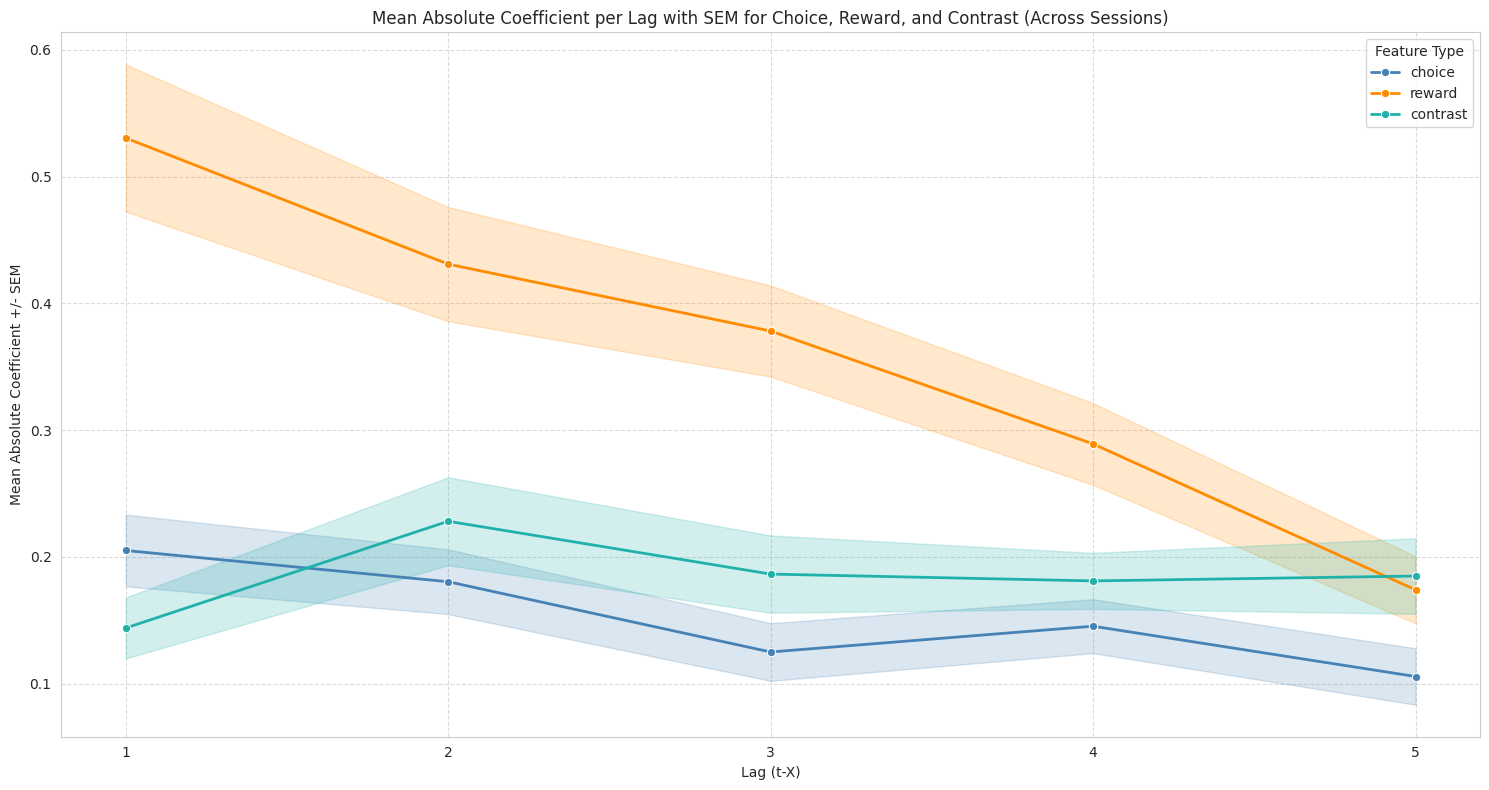

In [80]:
plot_wide_time_coefficients_SEM(coefficients_results_wide_time)

In [ ]:
def plot_static_lag_histogram(cv_results_static_df, sample_counts=1000, confidence_level=0.95):
    """
    Generates a histogram for the distribution of optimal static lags across sessions,
    and prints the mean and bootstrapped confidence interval.

    Args:
        cv_results_static_df (pd.DataFrame): DataFrame containing an 'optimum' column
                                            representing the optimal static lags.
        sample_counts (int): Number of bootstrapped samples to generate.
        confidence_level (float): The desired confidence level for the interval (e.g., 0.95 for 95% CI).
    """
    optimal_static_lags = cv_results_static_df['optimum'].dropna().values

    if len(optimal_static_lags) == 0:
        print("No data available for optimal static lags.")
        return

    alpha = 1 - confidence_level
    lower_percentile = alpha / 2 * 100
    upper_percentile = (1 - alpha / 2) * 100

    # Generate bootstrapped samples of the optimal static lags
    bootstrapped_raw_samples = bootstrap_samples(optimal_static_lags, sample_counts)
    bootstrapped_means = np.mean(bootstrapped_raw_samples, axis=1)

    mean_lag = np.mean(bootstrapped_means)
    ci_lower = np.percentile(bootstrapped_means, lower_percentile)
    ci_upper = np.percentile(bootstrapped_means, upper_percentile)

    print(f"\n--- Optimal Static Lag Distribution Statistics ({confidence_level*100:.0f}% Bootstrapped CI) ---")
    print(f"  Mean Optimal Static Lag: {mean_lag:.2f}")
    print(f"  {confidence_level*100:.0f}% CI for Mean: [{ci_lower:.2f}, {ci_upper:.2f}]")

    plt.figure(figsize=(10, 6))
    # Plot the distribution of bootstrapped means for a more continuous histogram
    sns.histplot(bootstrapped_means, kde=True, bins='auto', stat='density') # Changed stat to 'density'
    plt.title('Density Distribution of Bootstrapped Mean Optimal Static Lags Across Sessions') # Updated title
    plt.xlabel('Bootstrapped Mean Optimal Static Lag Value')
    plt.ylabel('Density') # Updated y-axis label
    # Removed explicit xticks as bins='auto' might not align with integer ticks
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


In [ ]:
def fetch_data(eid):
    """
    Fetches trial data for a given session ID, filters for valid rows,
    and returns specific columns.

    Args:
        eid (str): The experiment/session ID.

    Returns:
        pandas.DataFrame: A DataFrame containing filtered trial data with specified columns.
    """
    one = ONE()
    sess_loader = SessionLoader(eid=eid, one=one)
    sess_loader.load_trials()

    trials = sess_loader.trials

    # Define valid rows: stimOn_times not NaN and choice not 0 (no-go)
    valid_trials_idx = ~np.isnan(trials['stimOn_times']) & (trials['choice'] != 0) & (trials['probabilityLeft']!= 0.5)

    # Filter trials and select specified columns
    # Ensure trials is converted to a DataFrame before column selection if it's an ALF object
    filtered_data = trials.loc[valid_trials_idx, [
        'contrastLeft', 'contrastRight', 'probabilityLeft', 'rewardVolume', 'choice'
    ]]
    filtered_data=filtered_data.fillna(0)
    filtered_data['reward']=np.where(filtered_data['rewardVolume']!=0, filtered_data['choice'], 0)

    filtered_data['contrast']=filtered_data['contrastLeft']-filtered_data['contrastRight']
    filtered_data['block']=np.where(filtered_data['probabilityLeft']>50,1,-1)


    return filtered_data.reset_index().drop(['index','contrastRight','contrastLeft', 'probabilityLeft','rewardVolume'],axis=1)

# Demonstration of the function
# Using the same eid as in previous examples
# demo_eid = '4720c98a-a305-4fba-affb-bbfa00a724a4'

data=[]
for i,session in enumerate(SESSIONS):

  print(f'Session {i+1} of {len(SESSIONS)} is being fetched.')
  session_data=fetch_data(session)
  data.append(session_data)
  # SESSIONS_ACCURACY.loc[i]=np.logical_and((session_data['reward']!=0), (session_data['contrast']==0)).astype(int).sum()/(session_data['contrast']==0).sum()
  SESSIONS_ACCURACY.loc[i]= (session_data['reward']!=0).astype(int).sum()/len(session_data)


# print(f"Shape of fetched data: {data.shape}")
# print("First 5 rows of fetched data:")
# print(data['contrast'].value_counts())
# display(data.head(20))

Session 1 of 40 is being fetched.
Session 2 of 40 is being fetched.
Session 3 of 40 is being fetched.
Session 4 of 40 is being fetched.
Session 5 of 40 is being fetched.
Session 6 of 40 is being fetched.
Session 7 of 40 is being fetched.
Session 8 of 40 is being fetched.
Session 9 of 40 is being fetched.
Session 10 of 40 is being fetched.
Session 11 of 40 is being fetched.
Session 12 of 40 is being fetched.
Session 13 of 40 is being fetched.
Session 14 of 40 is being fetched.
Session 15 of 40 is being fetched.
Session 16 of 40 is being fetched.
Session 17 of 40 is being fetched.
Session 18 of 40 is being fetched.
Session 19 of 40 is being fetched.
Session 20 of 40 is being fetched.
Session 21 of 40 is being fetched.
Session 22 of 40 is being fetched.
Session 23 of 40 is being fetched.
Session 24 of 40 is being fetched.
Session 25 of 40 is being fetched.
Session 26 of 40 is being fetched.
Session 27 of 40 is being fetched.
Session 28 of 40 is being fetched.
Session 29 of 40 is being fet

In [ ]:
class LagFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, lags):
        """
        lags = {
            "choice": maximum lag for choice,
            "reward": maximum lag for reward,
            "contrast": maximum lag for contrast
        }
        """
        self.lags = lags

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        for col, max_lag in self.lags.items():

            for lag in range(1, max_lag + 1):
                X[f"{col}_t-{lag}"] = X[col].shift(lag)

        # Unavailable history = 0
        X = X.fillna(0)

        return X


pipeline = Pipeline([
    ("lags", LagFeatures({
        "choice": 1,
        "reward": 1,
        "contrast": 1
    })),
])



In [ ]:
class ColumnDropper(BaseEstimator, TransformerMixin):
    def __init__(self, columns_to_drop):
        self.columns_to_drop = columns_to_drop

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.drop(columns=self.columns_to_drop, errors='ignore')


def find_best_lags(
    X,
    y,
    choice_range=range(2,7),
    reward_range=range(2,7),
    contrast_range=range(2,7),
    cv_splits=5
):
    """
    Find the best maximum lag for choice, reward and contrast.

    Example:
        choice_range=range(0, 4)
        reward_range=range(0, 11)
        contrast_range=range(0, 6)
    """

    pipeline = Pipeline([
        ("lags", LagFeatures({
            "choice": 1,
            "reward": 1,
            "contrast": 1
        })),
        ("drop_original", ColumnDropper(columns_to_drop=['choice', 'reward','contrast'])),
        ("regression", LogisticRegression(penalty=PENALTY,solver='liblinear')) # Added solver to suppress warning
    ])

    # All combinations of s, reward and choice
    param_grid = {
        "lags__lags": [
            {
                "choice": choice,
                "reward": reward,
                "contrast": contrast,
            }
            for choice in choice_range
            for reward in reward_range
            for contrast in contrast_range
        ]
    }

    cv = TimeSeriesSplit(n_splits=cv_splits)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy", # Changed scoring metric to accuracy
        n_jobs=-1
    )

    search.fit(X, y)

    best = search.best_params_["lags__lags"]

    return {
        "choice": best["choice"],
        "reward": best["reward"],
        "contrast": best["contrast"],
        "cv_score": search.best_score_,
        # "model": search.best_estimator_
    }


def find_best_lags_static(
    X,
    y,
    range_=range(2,7),
    cv_splits=5
):
    """
    Find the best maximum lag for choice, reward and contrast.

    Example:
        range=range(0, 4)
    """

    pipeline = Pipeline([
        ("lags", LagFeatures({
            "choice": 1,
            "reward": 1,
            "contrast": 1
        })),
        ("drop_original", ColumnDropper(columns_to_drop=['choice', 'reward','contrast'])),
        ("regression", LogisticRegression(penalty=PENALTY,solver='liblinear')) # Added solver to suppress warning
    ])

    # All combinations of s, reward and choice
    param_grid = {
        "lags__lags": [
            {
                "choice": val,
                "reward": val,
                "contrast": val,
            }
            for val in range_

        ]
    }

    cv = TimeSeriesSplit(n_splits=cv_splits)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy", # Changed scoring metric to accuracy
        n_jobs=-1
    )

    search.fit(X, y)

    best = search.best_params_["lags__lags"]

    return {
        "optimum": best["choice"],
        "cv_score": search.best_score_ # Added cv_score
        # "model": search.best_estimator_
    }

In [ ]:
def fit_model_and_get_coefficients(X, choice_lag=4, reward_lag=4, contrast_lag=4, n_splits=5):
  pipeline = Pipeline([
        ("lags", LagFeatures({
            "choice": choice_lag,
            "reward": reward_lag,
            "contrast": contrast_lag
        })),
        ("drop_original", ColumnDropper(columns_to_drop=['choice', 'reward','contrast'])),
        ("regression", LogisticRegression(penalty=PENALTY,solver='liblinear'))
    ])

  tscv = TimeSeriesSplit(n_splits=n_splits)
  fold_coefficients = []

  y_target = X['choice']

  for train_index, test_index in tscv.split(X):
    X_train_full = X.iloc[train_index]
    y_train_full = y_target.iloc[train_index]

    pipeline.fit(X_train_full, y_train_full)

    # Get the coefficients
    coefficients = pipeline.named_steps['regression'].coef_[0]

    # Get the feature names by applying the transformers to a small part of X_train_full
    # This is done to ensure the feature names match the coefficients after transformations
    temp_X_transformed = pipeline.named_steps['lags'].transform(X_train_full.head(1))
    final_features_df = pipeline.named_steps['drop_original'].transform(temp_X_transformed)
    feature_names = final_features_df.columns.tolist()

    coefficients_series = pd.Series(coefficients, index=feature_names)
    fold_coefficients.append(coefficients_series)

  # Average the coefficients across all folds
  averaged_coefficients = pd.DataFrame(fold_coefficients).mean()
  return averaged_coefficients

In [ ]:
# Take the first session data for demonstration
sample_session = data[0]

# 1. Apply LagFeatures
lag_transformer = LagFeatures({"choice": 3, "reward": 4, "contrast": 2}) # Using example lags
df_after_lags = lag_transformer.fit_transform(sample_session)
print("DataFrame after LagFeatures:")
display(df_after_lags.head())

DataFrame after LagFeatures:


,choice,reward,contrast,block,choice_t-1,choice_t-2,choice_t-3,reward_t-1,reward_t-2,reward_t-3,reward_t-4,contrast_t-1,contrast_t-2
0,-1.0,-1.0,-0.2500,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0000
1,-1.0,-1.0,-0.1250,-1,-1.0,0.0,0.0,-1.0,0.0,0.0,0.0,-0.2500,0.0000
2,-1.0,-1.0,-0.0625,-1,-1.0,-1.0,0.0,-1.0,-1.0,0.0,0.0,-0.1250,-0.2500
3,-1.0,-1.0,-0.2500,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,0.0,-0.0625,-0.1250
4,-1.0,-1.0,0.0000,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-0.2500,-0.0625


In [ ]:
transformed_data = pipeline.fit_transform(data[0])
display(transformed_data.head())

,choice,reward,contrast,block,choice_t-1,reward_t-1,contrast_t-1
0,-1.0,-1.0,-0.2500,-1,0.0,0.0,0.0000
1,-1.0,-1.0,-0.1250,-1,-1.0,-1.0,-0.2500
2,-1.0,-1.0,-0.0625,-1,-1.0,-1.0,-0.1250
3,-1.0,-1.0,-0.2500,-1,-1.0,-1.0,-0.0625
4,-1.0,-1.0,0.0000,-1,-1.0,-1.0,-0.2500


In [ ]:
all_results = []
for i,session in enumerate(data):
  print(f"Session {i+1} of {len(data)} is being validated.")
  result = find_best_lags(session,session['choice'])
  all_results.append(result)

cv_results = pd.DataFrame(all_results)

display(cv_results)

Session 1 of 40 is being validated.
Session 2 of 40 is being validated.
Session 3 of 40 is being validated.
Session 4 of 40 is being validated.
Session 5 of 40 is being validated.
Session 6 of 40 is being validated.
Session 7 of 40 is being validated.
Session 8 of 40 is being validated.
Session 9 of 40 is being validated.
Session 10 of 40 is being validated.
Session 11 of 40 is being validated.
Session 12 of 40 is being validated.
Session 13 of 40 is being validated.
Session 14 of 40 is being validated.
Session 15 of 40 is being validated.
Session 16 of 40 is being validated.
Session 17 of 40 is being validated.
Session 18 of 40 is being validated.
Session 19 of 40 is being validated.
Session 20 of 40 is being validated.
Session 21 of 40 is being validated.
Session 22 of 40 is being validated.
Session 23 of 40 is being validated.
Session 24 of 40 is being validated.
Session 25 of 40 is being validated.
Session 26 of 40 is being validated.
Session 27 of 40 is being validated.
Session 28

,choice,reward,contrast,cv_score
0,6,4,3,0.802564
1,3,5,6,0.792593
2,4,5,6,0.865517
3,3,6,3,0.815556
4,2,2,6,0.796154
5,4,2,5,0.819048
6,2,5,3,0.842353
7,2,6,3,0.812000
8,6,4,4,0.735135
9,4,5,2,0.827778



--- Optimal Lag Distribution Statistics (95% Bootstrapped CI) ---
  Metric: Choice
    Mean Optimal Lag: 3.15
    95% CI for Mean: [2.77, 3.58]
  Metric: Reward
    Mean Optimal Lag: 3.63
    95% CI for Mean: [3.17, 4.12]
  Metric: Contrast
    Mean Optimal Lag: 3.50
    95% CI for Mean: [3.05, 3.98]


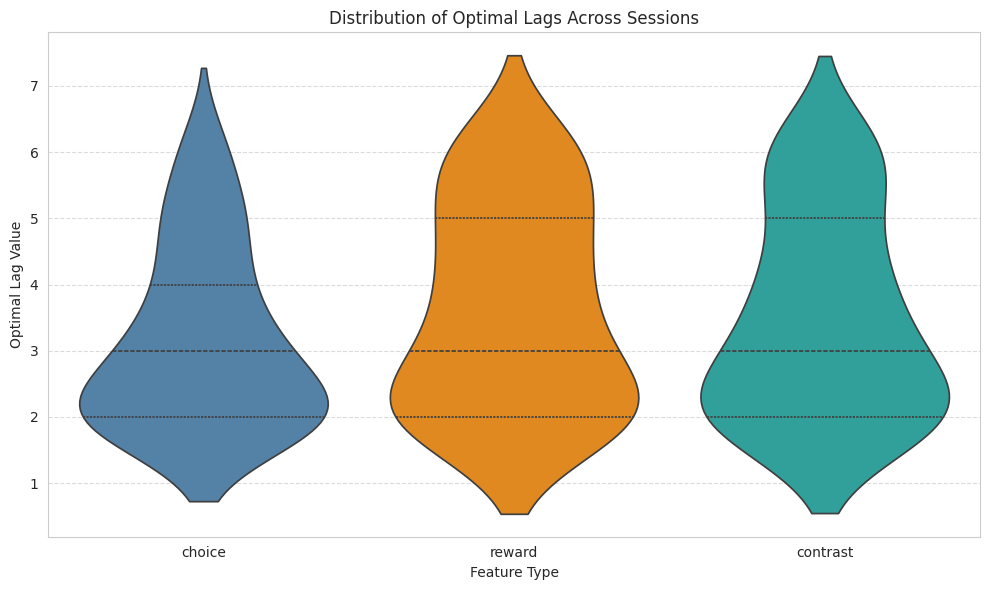

In [ ]:
plot_lag_distribution_violin(cv_results)

In [ ]:
all_static_results = []
for i,session in enumerate(data):
  print(f"Session {i+1} of {len(data)} is being validated")
  result = find_best_lags_static(session,session['choice'])
  all_static_results.append(result)

cv_results_static = pd.DataFrame(all_static_results)

display(cv_results_static)

Session 1 of 40 is being validated
Session 2 of 40 is being validated
Session 3 of 40 is being validated
Session 4 of 40 is being validated
Session 5 of 40 is being validated
Session 6 of 40 is being validated
Session 7 of 40 is being validated
Session 8 of 40 is being validated
Session 9 of 40 is being validated
Session 10 of 40 is being validated
Session 11 of 40 is being validated
Session 12 of 40 is being validated
Session 13 of 40 is being validated
Session 14 of 40 is being validated
Session 15 of 40 is being validated
Session 16 of 40 is being validated
Session 17 of 40 is being validated
Session 18 of 40 is being validated
Session 19 of 40 is being validated
Session 20 of 40 is being validated
Session 21 of 40 is being validated
Session 22 of 40 is being validated
Session 23 of 40 is being validated
Session 24 of 40 is being validated
Session 25 of 40 is being validated
Session 26 of 40 is being validated
Session 27 of 40 is being validated
Session 28 of 40 is being validated
S

,optimum,cv_score
0,4,0.800000
1,5,0.785185
2,4,0.862069
3,6,0.806667
4,3,0.792308
5,3,0.815873
6,5,0.837647
7,2,0.804000
8,4,0.732432
9,5,0.819444



--- Optimal Static Lag Distribution Statistics (95% Bootstrapped CI) ---
  Mean Optimal Static Lag: 3.75
  95% CI for Mean: [3.33, 4.17]


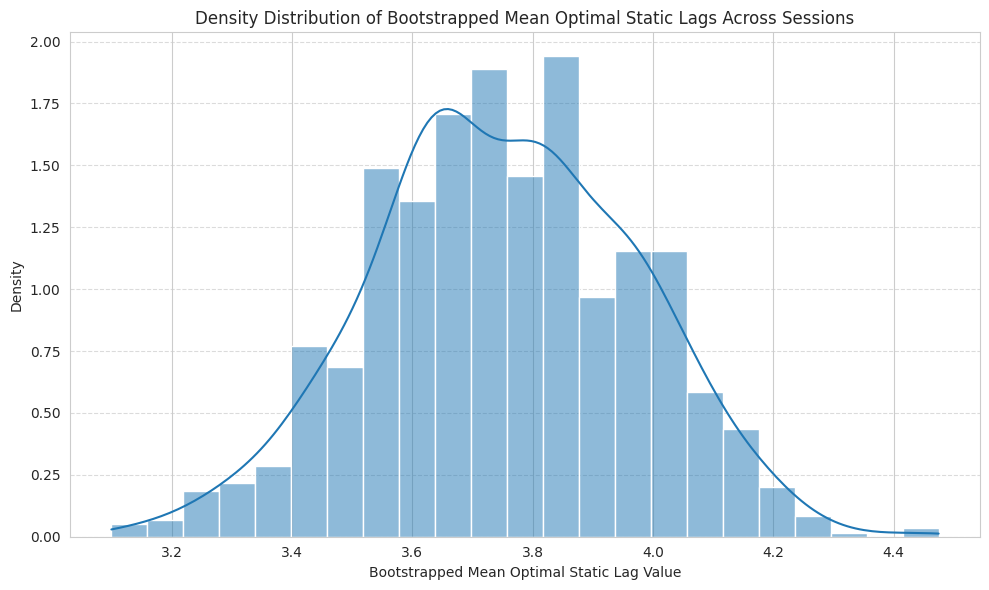

In [ ]:
plot_static_lag_histogram(cv_results_static)

In [ ]:
# This ensures each 'session' in the loop is a DataFrame.
data_for_processing = []
for i,session_id in enumerate(SESSIONS):
  print(f"Session {i+1} of {len(SESSIONS)} is being fetched.")
  data_for_processing.append(fetch_data(session_id))


Session 1 of 40 is being fetched.
Session 2 of 40 is being fetched.
Session 3 of 40 is being fetched.
Session 4 of 40 is being fetched.
Session 5 of 40 is being fetched.
Session 6 of 40 is being fetched.
Session 7 of 40 is being fetched.
Session 8 of 40 is being fetched.
Session 9 of 40 is being fetched.
Session 10 of 40 is being fetched.
Session 11 of 40 is being fetched.
Session 12 of 40 is being fetched.
Session 13 of 40 is being fetched.
Session 14 of 40 is being fetched.
Session 15 of 40 is being fetched.
Session 16 of 40 is being fetched.
Session 17 of 40 is being fetched.
Session 18 of 40 is being fetched.
Session 19 of 40 is being fetched.
Session 20 of 40 is being fetched.
Session 21 of 40 is being fetched.
Session 22 of 40 is being fetched.
Session 23 of 40 is being fetched.
Session 24 of 40 is being fetched.
Session 25 of 40 is being fetched.
Session 26 of 40 is being fetched.
Session 27 of 40 is being fetched.
Session 28 of 40 is being fetched.
Session 29 of 40 is being fet

In [ ]:
all_session_coefficients = [] # List to store coefficient series for each session

for i, session in enumerate(data_for_processing):
  print(f"Session {i+1} of {len(data_for_processing)} is being trained.")
  # Get coefficients for the current session
  session_coefficients = fit_model_and_get_coefficients(session)
  # Append the series to the list
  all_session_coefficients.append(session_coefficients)

# Create the final DataFrame where each row is a session and columns are the features
coefficients_results = pd.DataFrame(all_session_coefficients)

# display(coefficients_results)

Session 1 of 40 is being trained.
Session 2 of 40 is being trained.
Session 3 of 40 is being trained.
Session 4 of 40 is being trained.
Session 5 of 40 is being trained.
Session 6 of 40 is being trained.
Session 7 of 40 is being trained.
Session 8 of 40 is being trained.
Session 9 of 40 is being trained.
Session 10 of 40 is being trained.
Session 11 of 40 is being trained.
Session 12 of 40 is being trained.
Session 13 of 40 is being trained.
Session 14 of 40 is being trained.
Session 15 of 40 is being trained.
Session 16 of 40 is being trained.
Session 17 of 40 is being trained.
Session 18 of 40 is being trained.
Session 19 of 40 is being trained.
Session 20 of 40 is being trained.
Session 21 of 40 is being trained.
Session 22 of 40 is being trained.
Session 23 of 40 is being trained.
Session 24 of 40 is being trained.
Session 25 of 40 is being trained.
Session 26 of 40 is being trained.
Session 27 of 40 is being trained.
Session 28 of 40 is being trained.
Session 29 of 40 is being tra

Generating 1000 bootstrapped samples for each coefficient...

--- Feature: contrast ---
  Mean of bootstrapped coefficients: 5.7815
  95% CI for Mean: [5.0601, 6.5147]

--- Feature: block ---
  Mean of bootstrapped coefficients: 0.1119
  95% CI for Mean: [0.0212, 0.2085]

--- Feature: choice_t-1 ---
  Mean of bootstrapped coefficients: 0.0524
  95% CI for Mean: [-0.0529, 0.1375]

--- Feature: choice_t-2 ---
  Mean of bootstrapped coefficients: 0.1393
  95% CI for Mean: [0.0646, 0.2098]

--- Feature: choice_t-3 ---
  Mean of bootstrapped coefficients: 0.1160
  95% CI for Mean: [0.0584, 0.1735]

--- Feature: choice_t-4 ---
  Mean of bootstrapped coefficients: 0.1045
  95% CI for Mean: [0.0496, 0.1635]

--- Feature: reward_t-1 ---
  Mean of bootstrapped coefficients: 0.4730
  95% CI for Mean: [0.3495, 0.5969]

--- Feature: reward_t-2 ---
  Mean of bootstrapped coefficients: 0.2979
  95% CI for Mean: [0.2093, 0.3997]

--- Feature: reward_t-3 ---
  Mean of bootstrapped coefficients: 0.2082


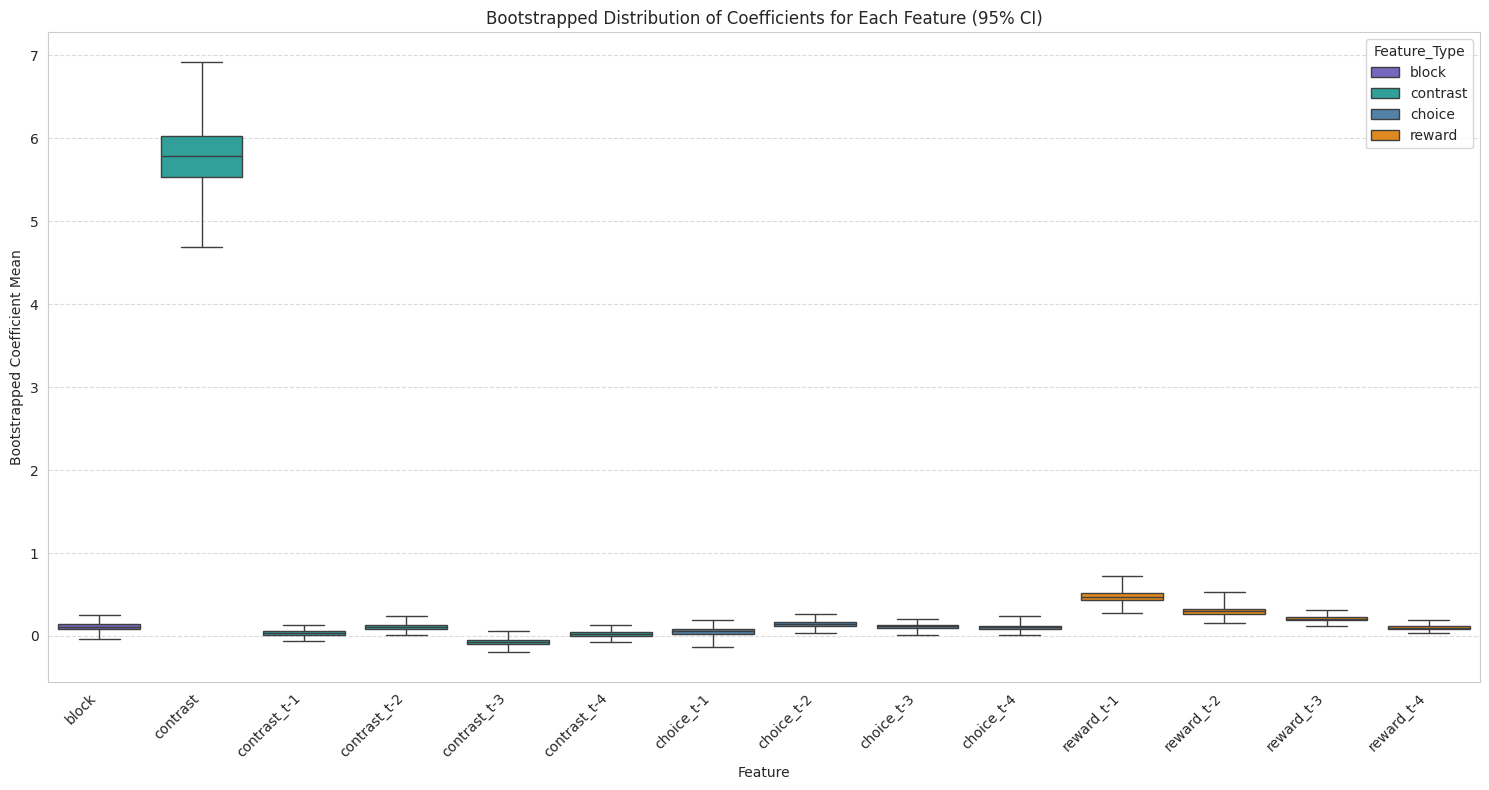

In [ ]:
 plot_coefficients_distribution(coefficients_results)

In [ ]:
# plot_coefficients_distribution(coefficients_results.drop(['contrast'],axis=1))

Generating 1000 bootstrapped samples for each absolute coefficient...

--- Feature: block (Absolute Value) ---
  Mean of bootstrapped absolute coefficients: 0.1582
  95% CI for Mean: [0.1041, 0.2215]

--- Feature: choice_t-1 (Absolute Value) ---
  Mean of bootstrapped absolute coefficients: 0.2076
  95% CI for Mean: [0.1512, 0.2668]

--- Feature: choice_t-2 (Absolute Value) ---
  Mean of bootstrapped absolute coefficients: 0.1905
  95% CI for Mean: [0.1409, 0.2410]

--- Feature: choice_t-3 (Absolute Value) ---
  Mean of bootstrapped absolute coefficients: 0.1287
  95% CI for Mean: [0.0875, 0.1721]

--- Feature: choice_t-4 (Absolute Value) ---
  Mean of bootstrapped absolute coefficients: 0.1528
  95% CI for Mean: [0.1159, 0.1942]

--- Feature: reward_t-1 (Absolute Value) ---
  Mean of bootstrapped absolute coefficients: 0.5430
  95% CI for Mean: [0.4281, 0.6526]

--- Feature: reward_t-2 (Absolute Value) ---
  Mean of bootstrapped absolute coefficients: 0.4430
  95% CI for Mean: [0.3613

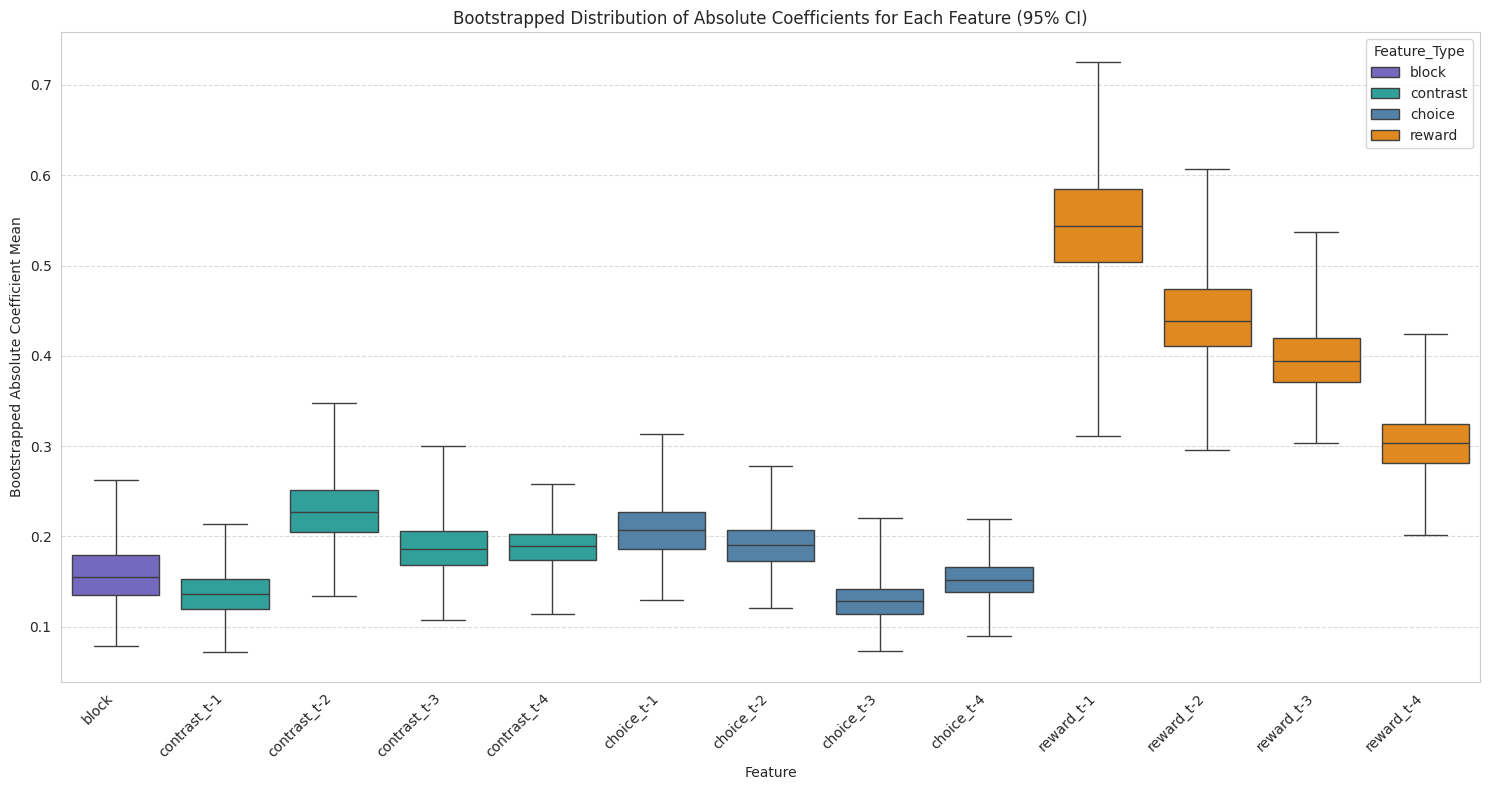

In [87]:
plot_coefficients_distribution_strength(coefficients_results)

--- Paired T-test Results on Absolute Coefficients ---
  Paired t-test (choice_t-2 vs choice_t-1): t-statistic=-0.665, p-value=0.5100 (ns)
  Paired t-test (choice_t-2 vs choice_t-3): t-statistic=1.686, p-value=0.0998 (ns)
  Paired t-test (reward_t-1 vs reward_t-2): t-statistic=1.467, p-value=0.1505 (ns)
  Paired t-test (reward_t-2 vs reward_t-3): t-statistic=0.936, p-value=0.3551 (ns)
  Paired t-test (reward_t-3 vs reward_t-4): t-statistic=1.916, p-value=0.0627 (ns)
  Paired t-test (block vs contrast_t-1): t-statistic=0.498, p-value=0.6212 (ns)
-----------------------------------------------------
Generating 1000 bootstrapped samples for each absolute coefficient...

--- Feature: block (Absolute Value) ---
  Mean of bootstrapped absolute coefficients: 0.1568
  95% CI for Mean: [0.1030, 0.2194]

--- Feature: choice_t-1 (Absolute Value) ---
  Mean of bootstrapped absolute coefficients: 0.2085
  95% CI for Mean: [0.1536, 0.2661]

--- Feature: choice_t-2 (Absolute Value) ---
  Mean of boot

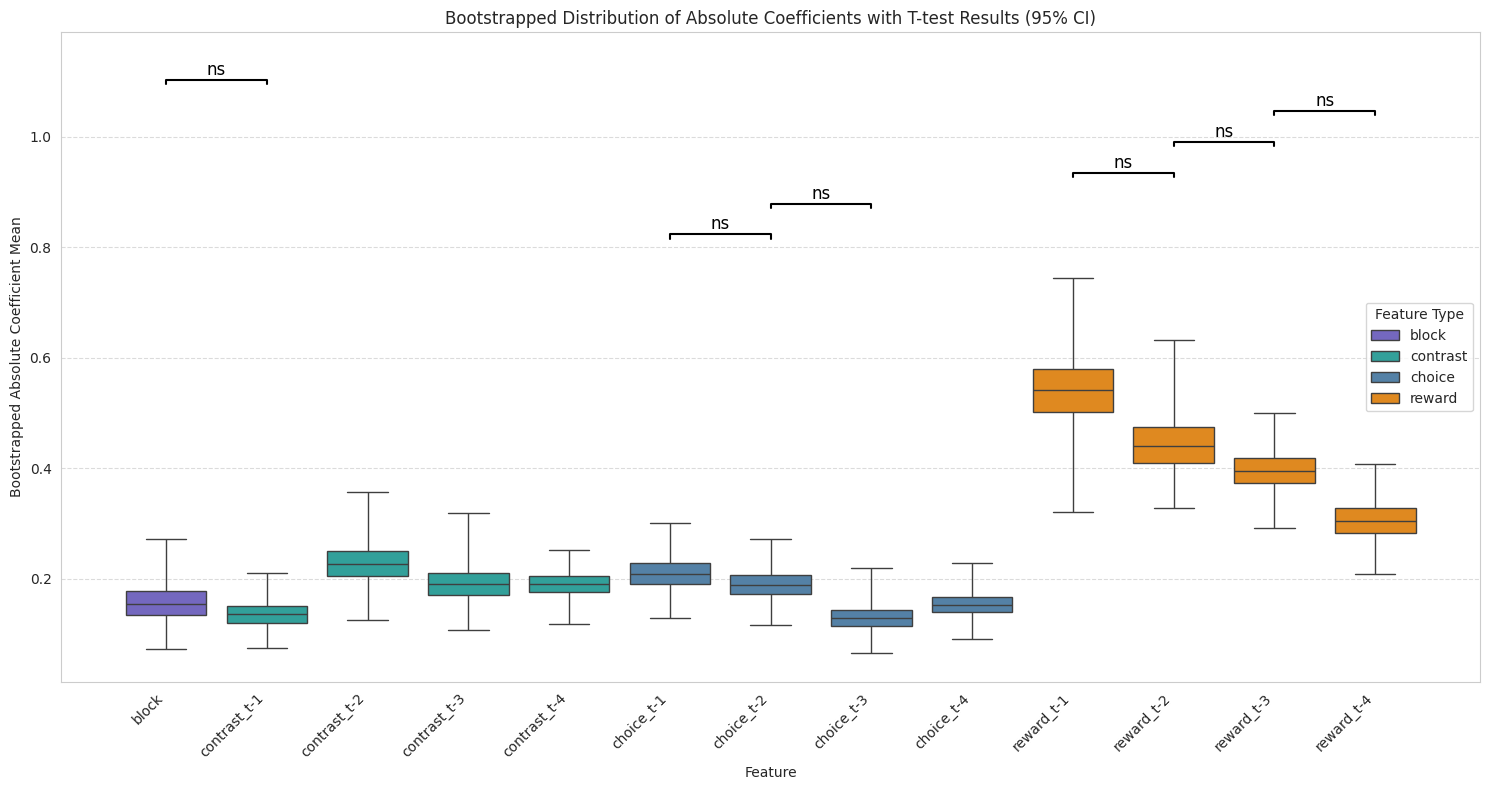

In [82]:
plot_coefficients_distribution_strength_t_test(coefficients_results,
                                               pairs_to_compare=[('choice_t-2', 'choice_t-1'), ('choice_t-2', 'choice_t-3'),
                                                                ('reward_t-1','reward_t-2'),('reward_t-2','reward_t-3'),('reward_t-3','reward_t-4'),
                                                                ('block','contrast_t-1')])

In [85]:
all_session_coefficients_wide_time = [] # List to store coefficient series for each session

for i, session in enumerate(data_for_processing):
  print(f"Session {i+1} of {len(data_for_processing)} is being trained.")
  # Get coefficients for the current session
  session_coefficients = fit_model_and_get_coefficients(session,choice_lag=5,reward_lag=5,contrast_lag=5)
  # Append the series to the list
  all_session_coefficients_wide_time.append(session_coefficients)

# Create the final DataFrame where each row is a session and columns are the features
coefficients_results_wide_time = pd.DataFrame(all_session_coefficients_wide_time)

display(coefficients_results_wide_time.abs())

Session 1 of 40 is being trained.
Session 2 of 40 is being trained.
Session 3 of 40 is being trained.
Session 4 of 40 is being trained.
Session 5 of 40 is being trained.
Session 6 of 40 is being trained.
Session 7 of 40 is being trained.
Session 8 of 40 is being trained.
Session 9 of 40 is being trained.
Session 10 of 40 is being trained.
Session 11 of 40 is being trained.
Session 12 of 40 is being trained.
Session 13 of 40 is being trained.
Session 14 of 40 is being trained.
Session 15 of 40 is being trained.
Session 16 of 40 is being trained.
Session 17 of 40 is being trained.
Session 18 of 40 is being trained.
Session 19 of 40 is being trained.
Session 20 of 40 is being trained.
Session 21 of 40 is being trained.
Session 22 of 40 is being trained.
Session 23 of 40 is being trained.
Session 24 of 40 is being trained.
Session 25 of 40 is being trained.
Session 26 of 40 is being trained.
Session 27 of 40 is being trained.
Session 28 of 40 is being trained.
Session 29 of 40 is being tra

,block,choice_t-1,choice_t-2,choice_t-3,choice_t-4,choice_t-5,reward_t-1,reward_t-2,reward_t-3,reward_t-4,reward_t-5,contrast_t-1,contrast_t-2,contrast_t-3,contrast_t-4,contrast_t-5
0,0.735720,0.507768,0.344436,0.000000,0.111345,0.029891,0.914740,0.589030,0.068254,0.319512,0.087694,0.146195,0.646295,0.124913,0.071567,0.133746
1,0.135507,0.070521,0.030629,0.012572,0.228359,0.035963,0.927902,0.377256,0.027266,0.627442,0.049823,0.001141,0.281378,0.185490,0.000000,0.104168
2,0.037848,0.006782,0.545011,0.194960,0.187348,0.184336,0.956331,0.145469,0.546940,0.451789,0.011700,0.297264,0.431331,0.101984,0.378733,0.424652
3,0.077488,0.279611,0.146566,0.052937,0.057796,0.164470,0.802459,0.007264,0.117732,0.018661,0.425080,0.018426,0.432429,0.102054,0.096043,0.096627
4,0.236335,0.566126,0.169456,0.181275,0.086128,0.577415,0.673630,0.069965,0.049542,0.301908,0.282389,0.084130,0.254857,0.006667,0.025807,0.680163
5,0.072056,0.406678,0.379313,0.033530,0.449731,0.015828,0.038175,0.112540,0.319210,0.740132,0.061381,0.047713,0.643487,0.004645,0.165867,0.110594
6,0.053376,0.332056,0.058417,0.053989,0.149108,0.001642,0.534052,0.464151,0.583031,0.102569,0.111048,0.089946,0.469734,0.036573,0.248539,0.021131
7,0.255336,0.402124,0.003413,0.065907,0.114814,0.075451,0.756874,0.413109,0.540254,0.219455,0.000000,0.128791,0.023218,0.611948,0.282859,0.028581
8,0.050256,0.234827,0.335989,0.052009,0.159132,0.200016,0.120637,0.213076,0.368388,0.568103,0.083817,0.126180,0.029485,0.085167,0.043867,0.018425
9,0.375945,0.040018,0.196228,0.017379,0.002939,0.126414,0.119602,0.412256,0.507158,0.131206,0.588110,0.057516,0.280358,0.091971,0.252515,0.163217


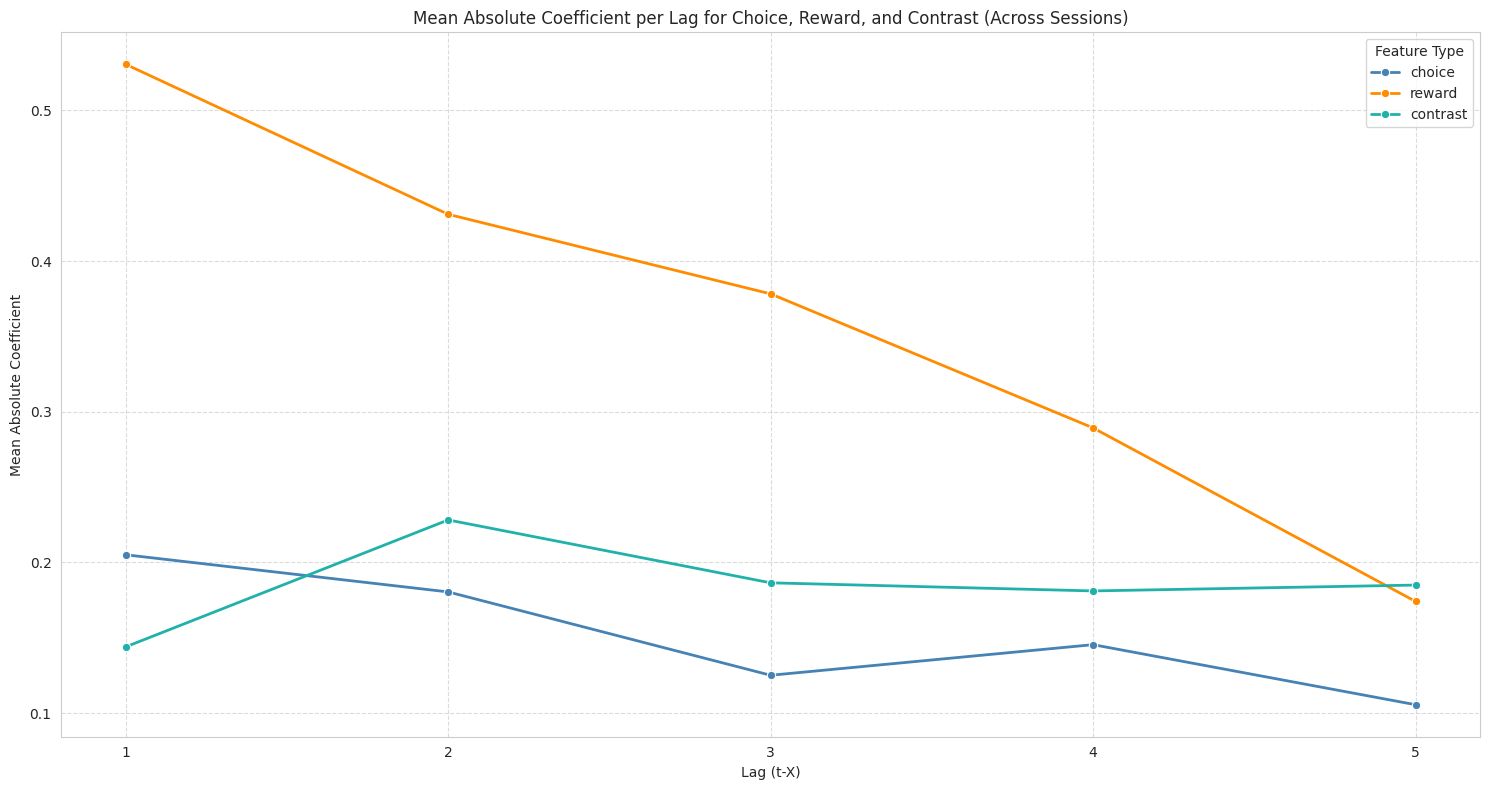

In [86]:
plot_wide_time_coefficients(coefficients_results_wide_time)

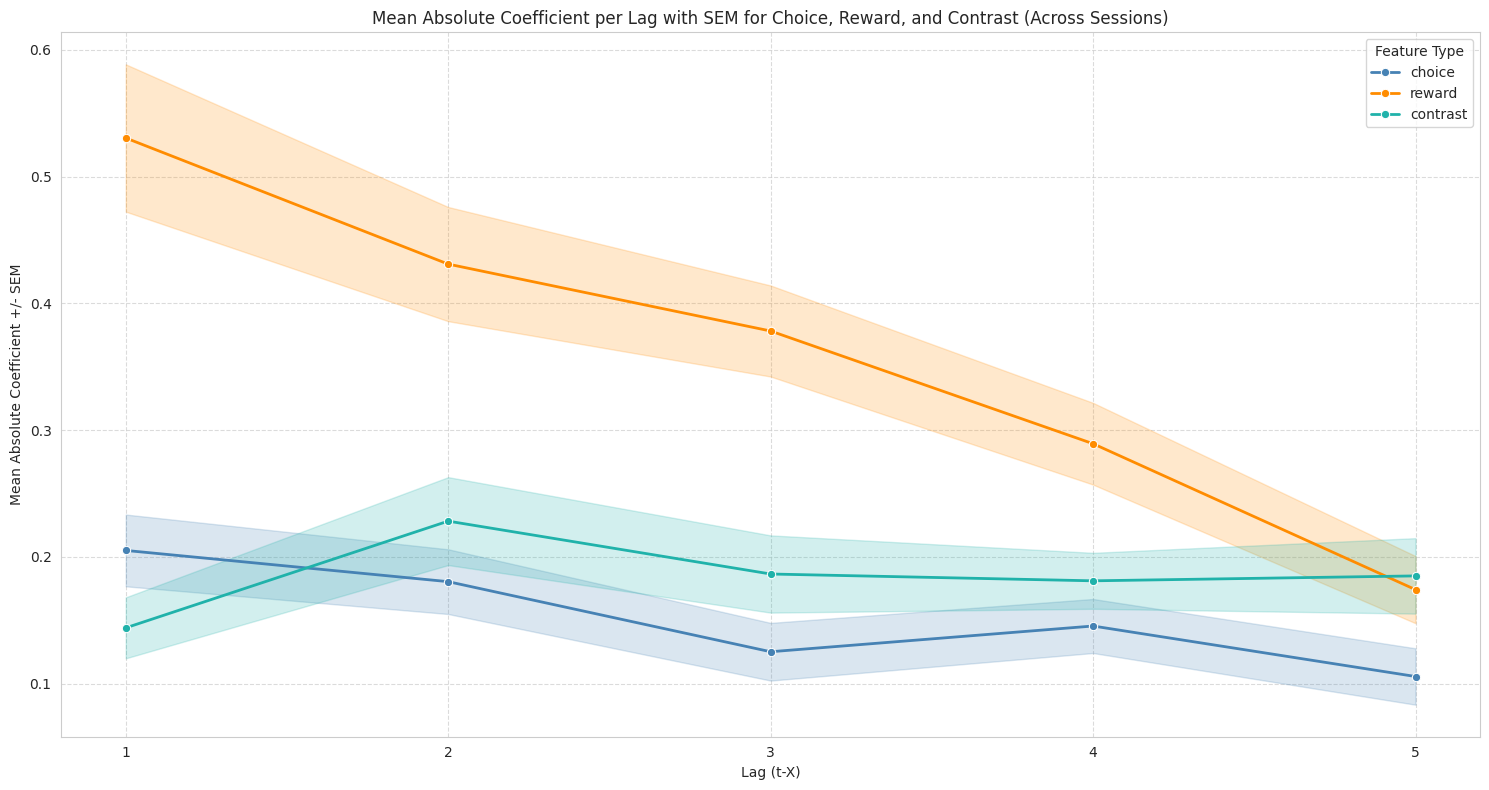

In [89]:
plot_wide_time_coefficients_SEM(coefficients_results_wide_time)

--- Contrast Lag vs. Session Accuracy ---
  R-squared: 0.000
  P-value: 0.9100


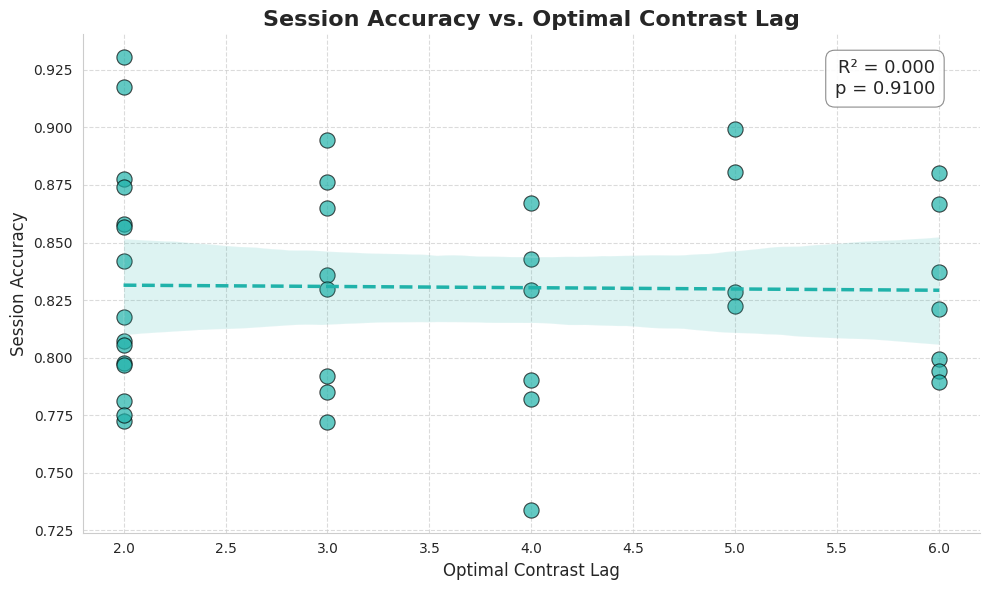

In [ ]:
lag_session_accuracy_plot(cv_results, 'contrast', SESSIONS_ACCURACY)

--- Reward Lag vs. Session Accuracy ---
  R-squared: 0.018
  P-value: 0.4112


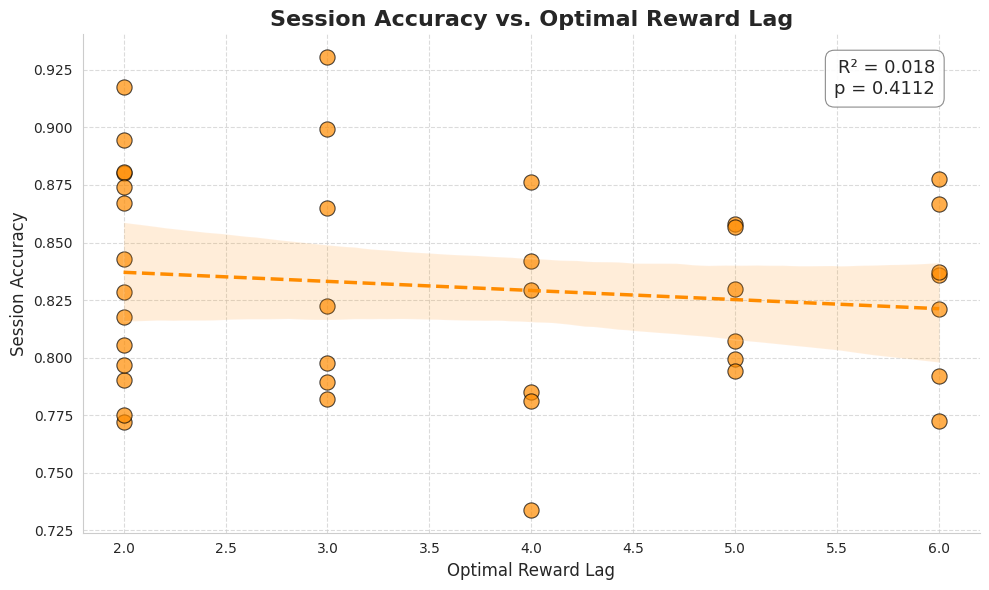

In [ ]:
lag_session_accuracy_plot(cv_results, 'reward', SESSIONS_ACCURACY)

--- Choice Lag vs. Session Accuracy ---
  R-squared: 0.332
  P-value: 0.0001


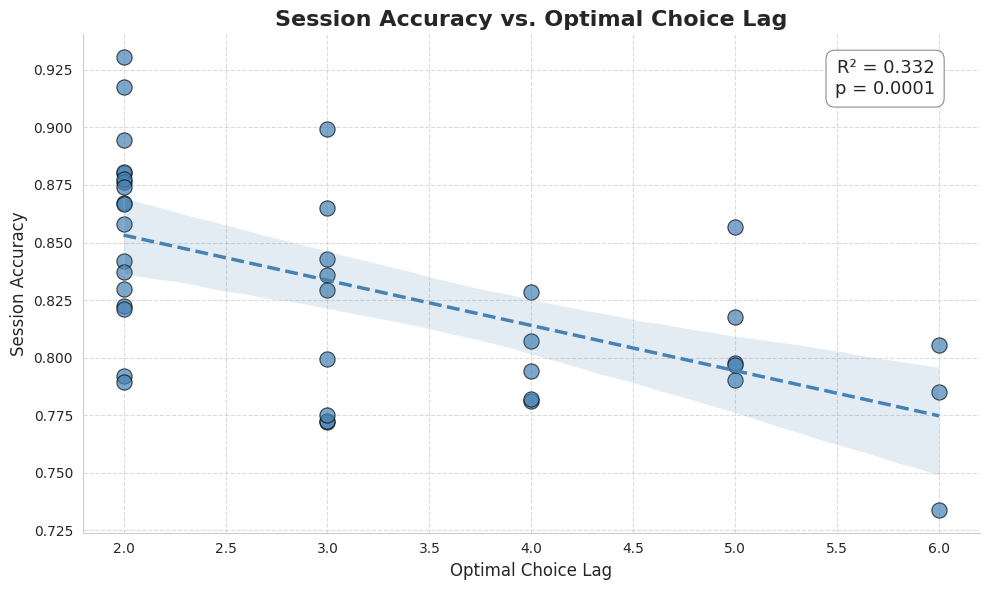

In [ ]:
lag_session_accuracy_plot(cv_results, 'choice', SESSIONS_ACCURACY)

--- Session Accuracy vs. CV Score ---
  R-squared: 0.438
  P-value: 0.0000


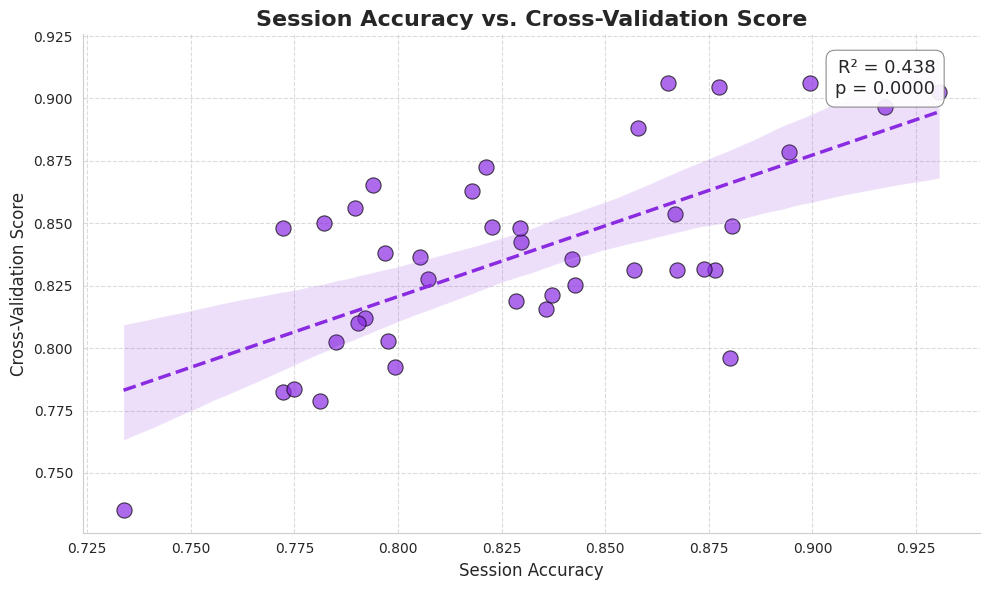

In [ ]:
plot_accuracy_vs_cv_score(cv_results, SESSIONS_ACCURACY)

In [ ]:
for session in data:
  print(session.shape)

(470, 4)
(329, 4)
(699, 4)
(542, 4)
(317, 4)
(379, 4)
(511, 4)
(303, 4)
(447, 4)
(436, 4)
(435, 4)
(468, 4)
(1010, 4)
(606, 4)
(816, 4)
(566, 4)
(398, 4)
(318, 4)
(422, 4)
(461, 4)
(744, 4)
(414, 4)
(352, 4)
(445, 4)
(682, 4)
(698, 4)
(399, 4)
(542, 4)
(681, 4)
(538, 4)
(725, 4)
(784, 4)
(417, 4)
(537, 4)
(460, 4)
(650, 4)
(493, 4)
(426, 4)
(496, 4)
(520, 4)
